# Análise dos resultados da calibração por algoritmo genético

O estudo estima $r$ (crescimento das presas), $K$ (capacidade de suporte),
$a$ (taxa de ataque), $h$ (tempo de manipulação), $e$ (eficiência de conversão)
e $m$ (mortalidade dos predadores) no modelo de Rosenzweig–MacArthur.

A análise usa o experimento salvo em `dados/resultados/ag_atual/experimento.json`.
Execute todas as células em ordem. São feitas integrações para reconstruir as trajetórias,
com o modelo de `data.py` e o integrador registrado no experimento.
Os artefatos são gravados em `trabalhofinal/analise_resultados/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.stats import qmc

candidatas = (Path.cwd(), Path.cwd() / "trabalhofinal", Path.cwd().parent)
raiz = next((p for p in candidatas if (p / "codigo" / "persistencia_ag.py").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abra o notebook a partir da pasta codigo, trabalhofinal ou da raiz da disciplina.")
sys.path.insert(0, str(raiz / "codigo"))
from data import rosenzweig_macarthur
from persistencia_ag import carregar_experimento

origem = raiz / "dados/resultados/ag_atual"
saida = raiz / "analise_resultados"
arquivo_shap = origem / "shap.csv"  # Edite este caminho para apontar para uma exportação SHAP.
parametros = ["r", "K", "a", "h", "e", "m"]
rotulos = [f"${p}$" for p in parametros]
populacoes = ["Presas", "Predadores"]
chaves = ["ruido", "realizacao", "execucao"]

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 12, "axes.labelsize": 12, "axes.titlesize": 13,
    "legend.fontsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "pdf.fonttype": 42, "figure.dpi": 105,
    "figure.constrained_layout.use": True, "figure.max_open_warning": 0,
})
paleta = ["#0072B2", "#D55E00", "#009E73"]


def rotulo_ruido(ruido):
    return f"{ruido:.0%}"


def id_ruido(ruido):
    return f"{100 * ruido:02.0f}"


def salvar_figura(fig, categoria, nome, mostrar=True):
    pasta = saida / "figuras" / categoria
    pasta.mkdir(parents=True, exist_ok=True)
    fig.savefig(pasta / f"{nome}.png", dpi=300)
    fig.savefig(pasta / f"{nome}.pdf")
    if mostrar:
        plt.show()
    plt.close(fig)


def latex_valor(valor):
    if pd.isna(valor):
        return "—"
    if isinstance(valor, (float, np.floating)):
        return f"{valor:.4g}"
    especiais = {
        "\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$",
        "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}",
        "~": r"\textasciitilde{}", "^": r"\textasciicircum{}",
    }
    return "".join(especiais.get(c, c) for c in str(valor))


def salvar_tabela(tabela, nome, mostrar=False):
    for formato in ("csv", "latex"):
        (saida / "tabelas" / formato).mkdir(parents=True, exist_ok=True)
    tabela.to_csv(saida / "tabelas" / "csv" / f"{nome}.csv", na_rep="")

    # Cabeçalhos planos permitem incluir o tabular com booktabs no Beamer.
    dados_latex = tabela.copy()
    if isinstance(dados_latex.columns, pd.MultiIndex):
        dados_latex.columns = [" / ".join(map(str, coluna)) for coluna in dados_latex.columns]
    dados_latex = dados_latex.reset_index()
    colunas = "".join("r" if pd.api.types.is_numeric_dtype(serie) else "l"
                      for _, serie in dados_latex.items())
    separador = r" \\"
    linhas = [r"\begin{tabular}{" + colunas + "}", r"\toprule",
              " & ".join(map(latex_valor, dados_latex.columns)) + separador, r"\midrule"]
    linhas.extend(" & ".join(map(latex_valor, linha)) + separador
                  for linha in dados_latex.itertuples(index=False, name=None))
    linhas.extend([r"\bottomrule", r"\end{tabular}"])
    (saida / "tabelas" / "latex" / f"{nome}.tex").write_text("\n".join(linhas) + "\n", encoding="utf-8")
    if mostrar:
        display(tabela)


def colorir_caixas(ax, valores, posicoes, cores, largura=0.65):
    caixas = ax.boxplot(valores, positions=posicoes, widths=largura, patch_artist=True,
                       manage_ticks=False, medianprops={"color": "black"})
    for caixa, cor in zip(caixas["boxes"], cores):
        caixa.set(facecolor=cor, alpha=0.55)
    ax.grid(axis="y", alpha=0.22)


def caixas_por_ruido(ax, tabela, coluna, ylabel):
    valores = [tabela.loc[tabela.ruido.eq(r), coluna].dropna() for r in niveis]
    colorir_caixas(ax, valores, range(len(niveis)), cores.values())
    ax.set(xticks=range(len(niveis)), xticklabels=list(map(rotulo_ruido, niveis)),
           xlabel="Ruído", ylabel=ylabel)


def escala_custo(ax, valores):
    valores = np.asarray(valores)
    positivos = valores[np.isfinite(valores) & (valores > 0)]
    if positivos.size:
        if (valores == 0).any():
            ax.set_yscale("symlog", linthresh=positivos.min() / 2)
        else:
            ax.set_yscale("log")

## 1. Protocolo, dados disponíveis e integridade

O experimento usa 50 tempos em $[0,30]$, os parâmetros $(1,100,0{,}05,0{,}2,0{,}5,0{,}5)$
e as condições iniciais $(40,10)$. O desvio-padrão do ruído gaussiano é uma
fração da amplitude da trajetória limpa de cada população. Há uma realização sem ruído
e três para cada nível com ruído, com 30 sementes do AG por realização.

Os metadados registram população de 100 indivíduos, torneio de 3, cruzamento com
probabilidade de 90%, mutação por gene de 25% com escala de 5% da faixa de busca,
3 elites, máximo de 150 gerações e paciência de 50 gerações com tolerância absoluta
$10^{-8}$. O notebook de calibração confirma o hipercubo latino, a correção por
`clip` e o cruzamento blend com $\lambda_j\sim U(-0{,}25,1{,}25)$. No código, os
dois filhos usam pesos complementares do mesmo sorteio em cada gene. Essa é a
variante de BLX-$\alpha$ usada aqui. A inicialização, a faixa de $\lambda$ e a
correção de limites são detalhes do código-fonte, pois o JSON não os registra
explicitamente.

O JSON contém estimativas vencedoras, custos finais, históricos do melhor custo e
do custo médio, sementes, gerações, avaliações, tempos, observações e trajetórias
limpas. A disponibilidade de populações, custos individuais e motivo de parada
é verificada abaixo. A penalidade $10^{12}$ identifica resultados vencedores
inválidos e sinaliza gerações com penalidades quando aparece no custo médio.
O histórico agregado pode sinalizar essas gerações, mas não guarda os vetores
que receberam a penalidade.

In [2]:
experimento = carregar_experimento(origem)
meta = experimento["metadados"]
registros = experimento["resultados"]
ag, dados, protocolo = (meta[k] for k in ("config_ag", "config_dados", "config_protocolo"))
verdade = pd.Series(meta["theta_true"], index=parametros, name="verdadeiro")
limites = np.asarray(ag["limites"])
niveis = sorted(protocolo["niveis_ruido"])
cores = dict(zip(niveis, paleta))
t = np.asarray(meta["dados_visualizacao"]["t"])
penalidade = 1e12

# As chaves distinguem a realização observacional da repetição do AG.
execucoes = pd.DataFrame(registros).reset_index(drop=True)
execucoes[parametros] = np.stack(execucoes["parametros"])
campos_opcionais = ["populacao_inicial", "populacao_final", "custos_populacao_final", "motivo_parada"]
disponibilidade = pd.DataFrame({
    "campo": campos_opcionais,
    "registros_com_campo": [sum(r.get(c) is not None for r in registros) for c in campos_opcionais],
}).set_index("campo")
grupos = execucoes.groupby(chaves[:2], sort=True)
protocolo_observado = grupos.agg(
    execucoes=("seed", "size"), sementes_ag=("seed", "nunique"), semente_dados=("seed_dados", "first"),
    sementes_dados_distintas=("seed_dados", "nunique"),
)
esperado = {(r, j) for r in niveis for j in range(1 if r == 0 else protocolo["n_realizacoes"])}
colunas_numericas = parametros + ["objetivo", "avaliacoes", "geracao_final", "tempo_segundos", "seed", "seed_dados"]


def dados_consistentes(grupo, campo):
    primeiro = grupo[campo].iloc[0]
    return (primeiro.shape == (len(t), 2) and np.isfinite(primeiro).all()
            and all(np.array_equal(primeiro, vetor) for vetor in grupo[campo]))


def historico_valido(registro):
    melhor = registro["historico_melhor"]
    medio = registro["historico_medio"]
    comprimento = registro["geracao_final"] + 1
    return (melhor.shape == medio.shape == (comprimento,)
            and np.isfinite(melhor).all() and np.isfinite(medio).all()
            and (melhor >= 0).all() and (medio >= melhor - 1e-12).all()
            and np.all(np.diff(melhor) <= 1e-12)
            and np.isclose(melhor[-1], registro["objetivo"], rtol=1e-10, atol=1e-14))


verificacoes = pd.Series({
    "Experimento concluído": experimento["completo"],
    "Chaves de execução únicas": not execucoes.duplicated(chaves).any(),
    "Realizações esperadas": set(grupos.groups) == esperado,
    "Contagem e sementes por realização": (
        protocolo_observado[["execucoes", "sementes_ag"]].eq(ag["n_execucoes"]).all().all()
        and protocolo_observado["sementes_dados_distintas"].eq(1).all()
        and protocolo_observado.reset_index().groupby("ruido")["semente_dados"].nunique()
            .eq(protocolo_observado.groupby(level="ruido").size()).all()
    ),
    "Valores numéricos finitos": np.isfinite(execucoes[colunas_numericas]).all().all(),
    "Estimativas dentro dos limites": np.all(
        (execucoes[parametros].to_numpy() >= limites[:, 0]) &
        (execucoes[parametros].to_numpy() <= limites[:, 1])),
    "Tempos e observações completos": (
        len(t) == dados["n_obs"] and np.isfinite(t).all()
        and np.all(np.diff(t) > 0) and np.allclose(t[[0, -1]], dados["t_span"])
        and all(dados_consistentes(g, c) for _, g in grupos for c in ("observacoes", "referencia"))),
    "Históricos consistentes": all(historico_valido(r) for r in registros),
})
configuracao = pd.DataFrame([{
    **{k: v for k, v in ag.items() if k != "limites"}, "n_obs": dados["n_obs"],
    "t_inicial": t[0], "t_final": t[-1], "normalizar_residuos": meta["normalizar_residuos"],
    "integrador_calibracao": meta["inversao"]["metodo"],
    **{f"verdadeiro_{p}": v for p, v in verdade.items()},
}])
salvar_tabela(configuracao, "configuracao_experimental")
salvar_tabela(pd.DataFrame(limites, index=parametros, columns=["inferior", "superior"]), "limites_busca")
salvar_tabela(disponibilidade, "disponibilidade_campos", mostrar=True)
salvar_tabela(verificacoes.rename("ok").to_frame(), "integridade", mostrar=True)
salvar_tabela(protocolo_observado, "protocolo_observado", mostrar=True)
if not verificacoes.all():
    raise ValueError(f"Revise as verificações de integridade: {verificacoes.index[~verificacoes].tolist()}")

diferencas = []
if len(execucoes) != 210 or niveis != [0.0, 0.02, 0.05]:
    diferencas.append("Contagens ou níveis de ruído diferentes da descrição inicial.")
if dados["n_obs"] != 50 or list(t[[0, -1]]) != [0, 30]:
    diferencas.append("Grade temporal diferente da descrição inicial.")
if not np.allclose(verdade, [1, 100, 0.05, 0.2, 0.5, 0.5]):
    diferencas.append("Parâmetros verdadeiros diferentes da descrição inicial.")
config_esperada = dict(tamanho_populacao=100, tamanho_torneio=3, elitismo=3, max_geracoes=150,
                       prob_cruzamento=0.9, prob_mutacao=0.25, escala_mutacao=0.05, paciencia=50,
                       tolerancia=1e-8, n_execucoes=30)
diferencas.extend(f"{k} = {ag[k]} (descrito: {v})" for k, v in config_esperada.items() if ag[k] != v)
print("Diferenças em relação à descrição:", "; ".join(diferencas) if diferencas else "nenhuma nas configurações numéricas verificadas.")

Diferenças em relação à descrição: nenhuma nas configurações numéricas verificadas.


,registros_com_campo
campo,
populacao_inicial,0
populacao_final,0
custos_populacao_final,0
motivo_parada,0


,ok
Experimento concluído,True
Chaves de execução únicas,True
Realizações esperadas,True
Contagem e sementes por realização,True
Valores numéricos finitos,True
Estimativas dentro dos limites,True
Tempos e observações completos,True
Históricos consistentes,True


execucoes  ...  sementes_dados_distintas
ruido realizacao             ...                          
0.00  0                  30  ...                         1
0.02  0                  30  ...                         1
      1                  30  ...                         1
      2                  30  ...                         1
0.05  0                  30  ...                         1
      1                  30  ...                         1
      2                  30  ...                         1

[7 rows x 4 columns]

## 2. Recuperação dos parâmetros

Em cada execução, calculamos $EA_j=|\hat\theta_j-\theta_j^*|$ e
$ER_j=100\,EA_j/|\theta_j^*|$. O erro médio da execução é a média dos seis
$ER_j$. Para a taxa de sucesso, usamos o maior dos seis erros e o limiar
registrado no experimento. As barras de dispersão representam o desvio-padrão
amostral entre as estimativas de um nível de ruído.

O primeiro radar usa $\hat\theta_j/\theta_j^*$, com o valor verdadeiro em 1.
Uma média próxima de 1 pode ocorrer quando desvios de sinais opostos se
compensam. O segundo radar, baseado no erro absoluto médio, ajuda a detectar isso.

,verdadeiro,media,mediana,DP,Q1,Q3,minimo,maximo,erro_absoluto_medio,ER_medio_pct,ER_mediano_pct,ER_DP_pct
parâmetro,,,,,,,,,,,,
r,1.00,1.033870,1.032055,0.072003,1.000820,1.064936,0.838580,1.193004,0.059942,5.994227,5.144637,5.151821
K,100.00,86.260272,84.879049,11.780553,77.749134,92.229162,68.952845,123.684424,15.954218,15.954218,18.423558,8.411719
a,0.05,0.055549,0.055201,0.006247,0.052424,0.060820,0.039275,0.068042,0.006827,13.654760,10.521408,9.518021
h,0.20,0.306119,0.299608,0.089711,0.244434,0.372303,0.111013,0.488588,0.115594,57.796885,52.836904,38.324181
e,0.50,0.629902,0.604076,0.124256,0.533221,0.720352,0.431840,0.892660,0.143206,28.641289,20.815133,21.615487
m,0.50,0.600448,0.605743,0.088765,0.528772,0.662878,0.456878,0.793017,0.106926,21.385265,21.148682,16.111547


,verdadeiro,media,mediana,DP,Q1,Q3,minimo,maximo,erro_absoluto_medio,ER_medio_pct,ER_mediano_pct,ER_DP_pct
parâmetro,,,,,,,,,,,,
r,1.00,1.033712,1.030031,0.060622,1.009955,1.063002,0.857785,1.203856,0.053345,5.334459,3.837889,4.412076
K,100.00,85.199773,83.696634,8.671030,78.491711,91.769935,66.647811,106.688043,15.293731,15.293731,16.303366,7.756828
a,0.05,0.055667,0.055715,0.005405,0.052608,0.058347,0.042404,0.078990,0.006507,13.013148,12.212144,8.689645
h,0.20,0.309983,0.305254,0.075227,0.250566,0.366511,0.174132,0.504785,0.112279,56.139433,52.626985,35.857566
e,0.50,0.632999,0.618685,0.111300,0.549514,0.724001,0.428844,0.877508,0.143063,28.612698,23.736910,19.573543
m,0.50,0.604590,0.587108,0.080495,0.542717,0.665839,0.461932,0.850916,0.107960,21.591995,17.421598,15.172555


,verdadeiro,media,mediana,DP,Q1,Q3,minimo,maximo,erro_absoluto_medio,ER_medio_pct,ER_mediano_pct,ER_DP_pct
parâmetro,,,,,,,,,,,,
r,1.00,1.053445,1.053890,0.071606,1.024866,1.098762,0.823743,1.213402,0.072726,7.272612,6.498042,5.164613
K,100.00,84.585662,81.942772,9.690280,77.982539,89.466298,68.801313,118.120196,16.483472,16.483472,18.128001,7.708132
a,0.05,0.057534,0.057485,0.006359,0.054394,0.060403,0.039860,0.074270,0.008477,16.953029,15.207399,10.036242
h,0.20,0.314806,0.324420,0.076025,0.259700,0.370219,0.129141,0.467661,0.119413,59.706626,62.210070,34.236672
e,0.50,0.626857,0.630804,0.106613,0.559819,0.703262,0.410052,0.840796,0.141367,28.273448,26.160871,17.240169
m,0.50,0.608114,0.603922,0.079596,0.553506,0.660394,0.445980,0.800553,0.114183,22.836525,20.784384,14.101451


,0%,2%,5%
parâmetro,,,
r,5.994227,5.334459,7.272612
K,15.954218,15.293731,16.483472
a,13.654760,13.013148,16.953029
h,57.796885,56.139433,59.706626
e,28.641289,28.612698,28.273448
m,21.385265,21.591995,22.836525


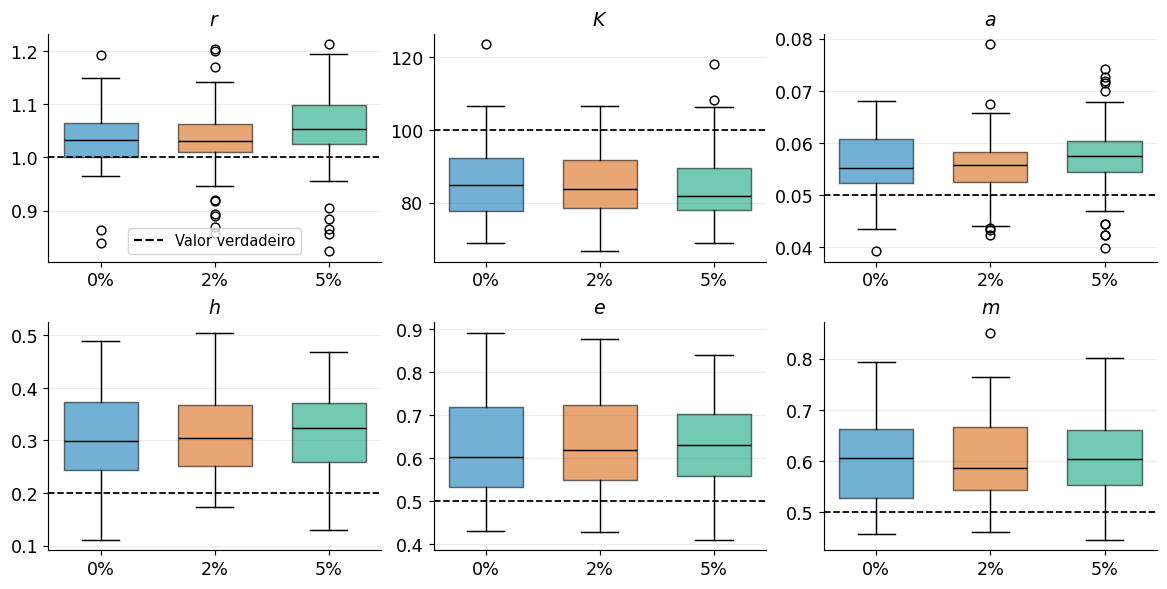

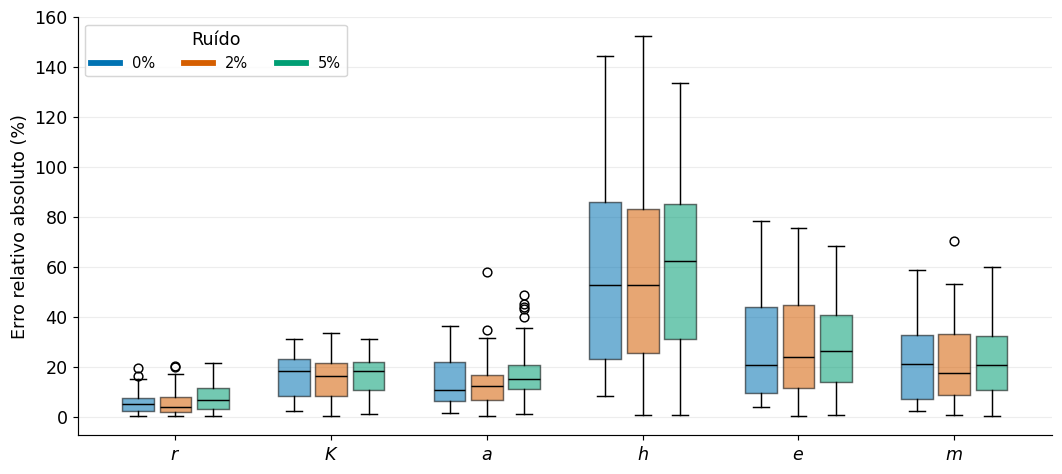

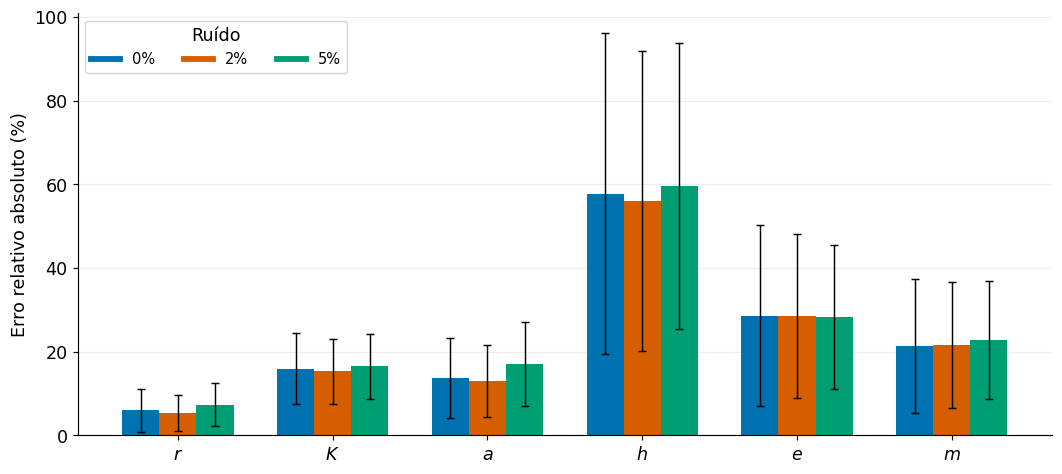

In [3]:
erros_absolutos = execucoes[parametros].sub(verdade).abs()
erros_relativos = 100 * erros_absolutos.div(verdade.abs())
execucoes["erro_medio_pct"] = erros_relativos.mean(axis=1)
execucoes["erro_max_pct"] = erros_relativos.max(axis=1)
execucoes["sucesso"] = execucoes.erro_max_pct.le(100 * execucoes.tolerancia_sucesso)
for p in parametros:
    execucoes[f"ER_{p}"] = erros_relativos[p]
estimativas_normalizadas = execucoes[parametros].div(verdade)
resumos = {}
for ruido, grupo in execucoes.groupby("ruido"):
    estimativas = grupo[parametros]
    er, ea = erros_relativos.loc[grupo.index], erros_absolutos.loc[grupo.index]
    resumo = pd.DataFrame({
        "verdadeiro": verdade, "media": estimativas.mean(), "mediana": estimativas.median(),
        "DP": estimativas.std(), "Q1": estimativas.quantile(.25), "Q3": estimativas.quantile(.75),
        "minimo": estimativas.min(), "maximo": estimativas.max(),
        "erro_absoluto_medio": ea.mean(), "ER_medio_pct": er.mean(),
        "ER_mediano_pct": er.median(), "ER_DP_pct": er.std(),
    })
    resumo.index.name = "parâmetro"
    resumos[ruido] = resumo
    salvar_tabela(resumo, f"tabela_recuperacao_ruido_{id_ruido(ruido)}", mostrar=True)
recuperacao = pd.DataFrame({rotulo_ruido(r): s.ER_medio_pct for r, s in resumos.items()})
salvar_tabela(recuperacao, "tabela_recuperacao_parametros", mostrar=True)


def perfil_estimativas(grupos_plot, nomes, cores_plot, categoria, arquivo):
    fig, eixos = plt.subplots(2, 3, figsize=(11, 5.5))
    for p, rotulo, ax in zip(parametros, rotulos, eixos.flat):
        colorir_caixas(ax, [g[p] for g in grupos_plot], range(len(nomes)), cores_plot)
        ax.axhline(verdade[p], color="black", ls="--", lw=1.2)
        ax.set(title=rotulo, xticks=range(len(nomes)), xticklabels=nomes)
    eixos.flat[0].legend(handles=[Line2D([], [], color="black", ls="--", label="Valor verdadeiro")],
                         loc="best")
    salvar_figura(fig, categoria, arquivo)


grupos_ruido = [execucoes[execucoes.ruido.eq(r)] for r in niveis]
perfil_estimativas(grupos_ruido, list(map(rotulo_ruido, niveis)), list(cores.values()),
                   "parametros", "boxplot_parametros_estimados")
posicoes = np.arange(len(parametros))
largura = .24
deslocamentos = (np.arange(len(niveis)) - (len(niveis) - 1) / 2) * largura
legenda_ruido = [Line2D([], [], color=cores[r], lw=4, label=rotulo_ruido(r)) for r in niveis]
for tipo in ("boxplot", "barras"):
    fig, ax = plt.subplots(figsize=(10, 4.4))
    for r, grupo, desloc in zip(niveis, grupos_ruido, deslocamentos):
        if tipo == "boxplot":
            colorir_caixas(ax, [erros_relativos.loc[grupo.index, p] for p in parametros],
                           posicoes + desloc, [cores[r]] * len(parametros), largura * .85)
        else:
            ax.bar(posicoes + desloc, resumos[r].ER_medio_pct, largura, color=cores[r],
                   yerr=resumos[r].ER_DP_pct, error_kw={"capsize": 3, "elinewidth": 1})
            ax.grid(axis="y", alpha=.22)
            ax.set_ylim(bottom=0)
    ax.set(xticks=posicoes, xticklabels=rotulos, ylabel="Erro relativo absoluto (%)")
    ax.legend(handles=legenda_ruido, title="Ruído", ncols=len(niveis), loc="upper left")
    salvar_figura(fig, "parametros", f"{tipo}_erro_relativo_parametros")

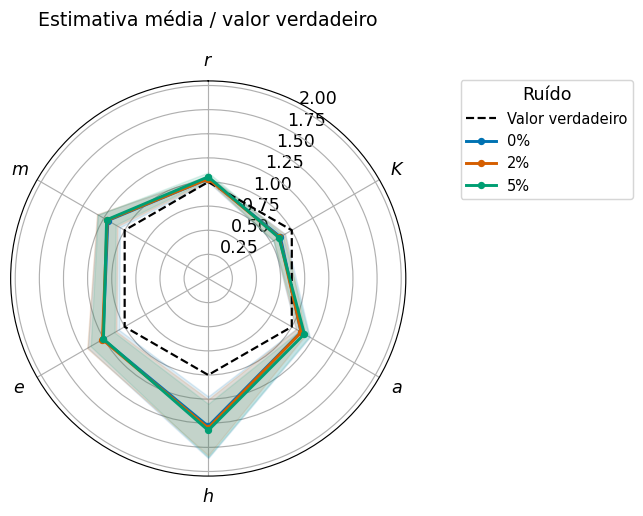

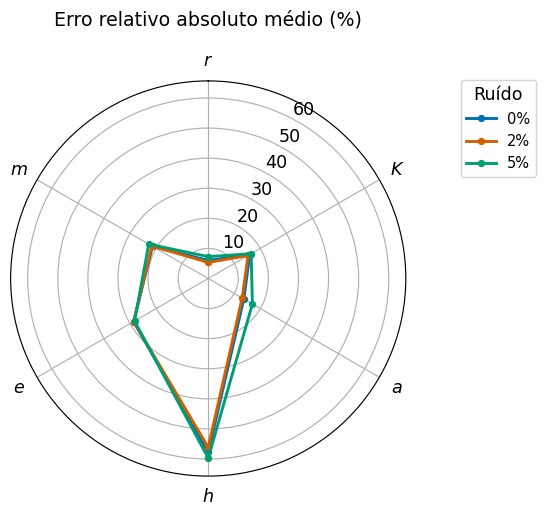

In [4]:
angulos = np.linspace(0, 2 * np.pi, len(parametros), endpoint=False)
angulos_fechados = np.r_[angulos, angulos[0]]


def fechar(valores):
    valores = np.asarray(valores, dtype=float)
    return np.r_[valores, valores[0]]


for usar_erros in (False, True):
    fig, ax = plt.subplots(figsize=(8.8, 4.8), subplot_kw={"projection": "polar"})
    if not usar_erros:
        ax.plot(angulos_fechados, np.ones(len(angulos_fechados)), "k--", lw=1.5, label="Valor verdadeiro")
    extremo = 1 if not usar_erros else 0
    for ruido, grupo in zip(niveis, grupos_ruido):
        valores = (erros_relativos if usar_erros else estimativas_normalizadas).loc[grupo.index]
        ax.plot(angulos_fechados, fechar(valores.mean()), color=cores[ruido], lw=2,
                marker="o", ms=4, label=rotulo_ruido(ruido))
        extremo = max(extremo, valores.mean().max())
        if not usar_erros:
            q1, q3 = valores.quantile([.25, .75]).to_numpy()
            ax.fill_between(angulos_fechados, fechar(q1), fechar(q3), color=cores[ruido], alpha=.12)
            extremo = max(extremo, q3.max())
    ax.set(xticks=angulos, xticklabels=rotulos, ylim=(0, extremo * 1.1))
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(28)
    ax.legend(title="Ruído", loc="upper left", bbox_to_anchor=(1.12, 1.02))
    ax.set_title("Erro relativo absoluto médio (%)" if usar_erros else "Estimativa média / valor verdadeiro", pad=18)
    salvar_figura(fig, "parametros", "radar_erro_relativo" if usar_erros else "radar_parametros_normalizados")

## 3. Ajuste das trajetórias por realização

Para cada população, $\mathrm{RMSE}=\sqrt{n^{-1}\sum_i(\hat y_i-y_i)^2}$.
Calculamos o RMSE contra as observações e contra a referência limpa. Em ambos
os casos, o NRMSE usa como denominador a amplitude da respectiva
trajetória **limpa**, para comparar níveis de ruído na mesma escala. O
NRMSE conjunto é a raiz da média dos quadrados dos NRMSEs das duas populações.
Já $J$ reproduz a calibração com a normalização pela amplitude **observada**.

O melhor vetor de cada realização é o de menor custo salvo, com desempate pela
semente. As faixas mostram quantis ponto a ponto entre as 30 reconstruções
daquela realização. Selecionamos, em cada nível de ruído, a realização cuja
mediana de $J$ é a mediana entre realizações, com desempate pelo menor
identificador. Produzimos figuras para todas as realizações e destacamos
as três representativas.

Reconstruções inválidas: 0
Vencedores penalizados: 0
Custos recalculados divergentes: 0


J_verdadeiro     J_min  ...  custos_reproduzidos  representativa
ruido realizacao                          ...                                     
0.00  0           7.216358e-17  0.000019  ...                   30            True
0.02  0           4.120311e-04  0.000405  ...                   30           False
      1           4.254324e-04  0.000433  ...                   30            True
      2           4.518975e-04  0.000447  ...                   30           False
0.05  0           2.453858e-03  0.002327  ...                   30            True
      1           2.461780e-03  0.002286  ...                   30           False
      2           2.730873e-03  0.002699  ...                   30           False

[7 rows x 12 columns]

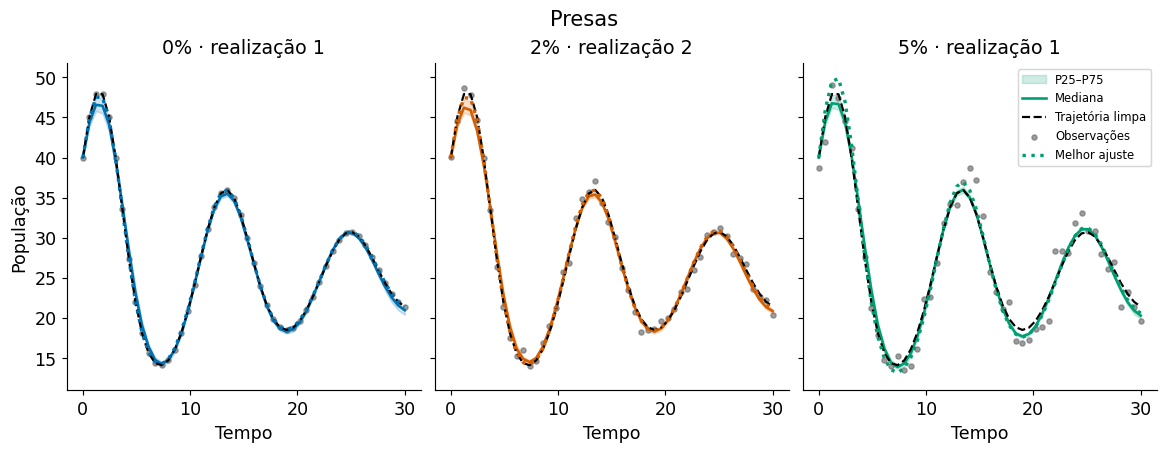

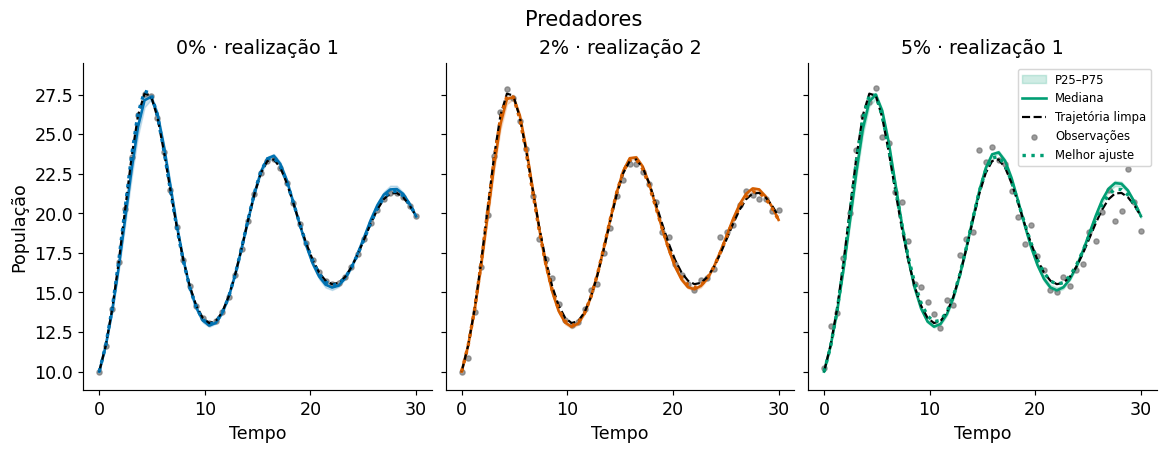

Com ruído, uma estimativa pode ter $J(\hat\theta)<J(\theta^*)$ ao ajustar parte da perturbação observacional. A comparação com a trajetória limpa e os erros dos parâmetros quantificam aspectos diferentes da recuperação.

In [5]:
inversao = meta["inversao"]


def simular(theta):
    try:
        solucao = solve_ivp(rosenzweig_macarthur, tuple(dados["t_span"]), meta["y0"],
                            t_eval=t, args=tuple(theta), method=inversao["metodo"],
                            rtol=inversao["rtol"], atol=inversao["atol"])
    except (ValueError, FloatingPointError, OverflowError):
        return None
    if solucao.success and solucao.y.shape == (2, len(t)):
        trajetoria = solucao.y.T
        if np.isfinite(trajetoria).all() and (trajetoria >= 0).all():
            return trajetoria
    return None


def amplitude(trajetoria):
    escala = np.ptp(trajetoria, axis=0)
    return np.where(escala > 0, escala, np.maximum(np.abs(trajetoria).max(axis=0), 1))


def custo_simulado(trajetoria, observado):
    if trajetoria is None:
        return penalidade
    residuo = trajetoria - observado
    if meta["normalizar_residuos"]:
        residuo = residuo / amplitude(observado)
    return float(np.mean(residuo**2))


simulacao_verdadeira = simular(verdade)
if simulacao_verdadeira is None:
    raise ValueError("Falha na reconstrução da trajetória nos parâmetros verdadeiros.")
previsoes = {}
metricas_trajetoria = []
for indice, registro in execucoes.iterrows():
    previsto = simular(registro[parametros].to_numpy(dtype=float))
    observacoes, referencia = registro["observacoes"], registro["referencia"]
    escala = amplitude(referencia)
    custos = {"J_estimado_recalculado": custo_simulado(previsto, observacoes),
              "J_verdadeiro": custo_simulado(simulacao_verdadeira, observacoes),
              "simulacao_valida": previsto is not None}
    previsoes[indice] = previsto
    for nome, alvo in (("obs", observacoes), ("ref", referencia)):
        rmse = (np.sqrt(np.mean((previsto - alvo)**2, axis=0)) if previsto is not None
                else np.full(2, np.nan))
        nrmse = rmse / escala
        custos.update({f"RMSE_{nome}_{p}": v for p, v in zip(("N", "P"), rmse)})
        custos.update({f"NRMSE_{nome}_{p}": v for p, v in zip(("N", "P"), nrmse)})
        custos[f"RMSE_{nome}"] = np.sqrt(np.mean(rmse**2))
        custos[f"NRMSE_{nome}"] = np.sqrt(np.mean(nrmse**2))
    metricas_trajetoria.append(custos)

execucoes = execucoes.join(pd.DataFrame(metricas_trajetoria, index=execucoes.index))
execucoes["J_igual_salvo"] = np.isclose(execucoes.J_estimado_recalculado, execucoes.objetivo, atol=1e-12, rtol=1e-8)
execucoes["J_abaixo_verdadeiro"] = execucoes.objetivo.lt(execucoes.J_verdadeiro)
execucoes["penalidade_final"] = execucoes.objetivo.ge(penalidade)
print("Reconstruções inválidas:", (~execucoes.simulacao_valida).sum())
print("Vencedores penalizados:", execucoes.penalidade_final.sum())
print("Custos recalculados divergentes:", (~execucoes.J_igual_salvo).sum())

por_realizacao = execucoes.groupby(chaves[:2]).agg(
    J_verdadeiro=("J_verdadeiro", "first"), J_min=("objetivo", "min"), J_mediano=("objetivo", "median"),
    J_max=("objetivo", "max"), abaixo_J_verdadeiro=("J_abaixo_verdadeiro", "sum"),
    RMSE_obs_mediano=("RMSE_obs", "median"), RMSE_ref_mediano=("RMSE_ref", "median"),
    NRMSE_obs_mediano=("NRMSE_obs", "median"), NRMSE_ref_mediano=("NRMSE_ref", "median"),
    simulacoes_validas=("simulacao_valida", "sum"), custos_reproduzidos=("J_igual_salvo", "sum"),
)
representativas = {}
for ruido in niveis:
    mediana = por_realizacao.loc[ruido, "J_mediano"]
    representativas[ruido] = int((mediana - mediana.median()).abs().sort_index().idxmin())
por_realizacao["representativa"] = [representativas[r] == j for r, j in por_realizacao.index]
salvar_tabela(por_realizacao, "tabela_ajuste_por_realizacao", mostrar=True)

# Todos os cenários compartilham escalas verticais por população.
limites_y = []
for k in range(2):
    amostras = [v[:, k] for v in previsoes.values() if v is not None]
    amostras += [v[:, k] for c in ("observacoes", "referencia") for v in execucoes[c]]
    minimo = min(np.min(a) for a in amostras)
    maximo = max(np.max(a) for a in amostras)
    margem = .05 * (maximo - minimo)
    limites_y.append((minimo - margem, maximo + margem))

def desenhar_trajetoria(ax, grupo, k, ruido):
    valido = grupo[grupo.simulacao_valida]
    if valido.empty:
        ax.text(.5, .5, "Sem trajetórias válidas", ha="center", transform=ax.transAxes)
        return
    melhor = valido.sort_values(["objetivo", "seed"]).index[0]
    trajetorias = np.stack([previsoes[i][:, k] for i in valido.index])
    q1, mediana, q3 = np.percentile(trajetorias, [25, 50, 75], axis=0)
    observado, referencia = grupo.iloc[0][["observacoes", "referencia"]]
    ax.fill_between(t, q1, q3, color=cores[ruido], alpha=.19, label="P25–P75")
    ax.plot(t, mediana, color=cores[ruido], lw=1.8, label="Mediana")
    ax.plot(t, referencia[:, k], color="black", ls="--", label="Trajetória limpa")
    ax.scatter(t, observado[:, k], s=12, color="#777777", alpha=.72, label="Observações")
    ax.plot(t, previsoes[melhor][:, k], color=cores[ruido], ls=":", lw=2.3,
            label="Melhor ajuste")
    ax.set(xlabel="Tempo", ylabel="População", ylim=limites_y[k])


grupos_trajetorias = execucoes.groupby(chaves[:2])
for (ruido, realizacao), grupo in grupos_trajetorias:
    fig, eixos = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
    for k, ax in enumerate(eixos):
        desenhar_trajetoria(ax, grupo, k, ruido)
        ax.set_title(populacoes[k])
    if eixos[1].get_legend_handles_labels()[0]:
        eixos[1].legend(loc="upper right", fontsize=9)
    fig.suptitle(f"Ruído {ruido:.0%} · realização {realizacao + 1}")
    salvar_figura(fig, "trajetorias", f"ajuste_trajetorias_ruido_{id_ruido(ruido)}_realizacao_{realizacao + 1:02d}",
                  mostrar=False)

for k, nome in enumerate(populacoes):
    fig, eixos = plt.subplots(1, len(niveis), figsize=(11, 4.2), sharey=True, squeeze=False)
    for ax, (ruido, j) in zip(eixos.flat, representativas.items()):
        desenhar_trajetoria(ax, grupos_trajetorias.get_group((ruido, j)), k, ruido)
        ax.set_title(f"{ruido:.0%} · realização {j + 1}")
    for ax in eixos.flat[1:]:
        ax.set_ylabel("")
    if eixos.flat[-1].get_legend_handles_labels()[0]:
        eixos.flat[-1].legend(loc="upper right", fontsize=8)
    fig.suptitle(nome)
    salvar_figura(fig, "trajetorias", f"ajuste_representativo_{nome.lower()}")

display(Markdown(
    r"Com ruído, uma estimativa pode ter $J(\hat\theta)<J(\theta^*)$ ao ajustar parte da "
    "perturbação observacional. A comparação com a trajetória limpa e os erros "
    "dos parâmetros quantificam aspectos diferentes da recuperação."
))

## 4. Convergência e orçamento de avaliações

O melhor custo é não crescente pelo elitismo. O custo médio da população acompanha
o efeito dos descendentes. As linhas finas mostram execuções individuais, a linha
espessa mostra a mediana e a faixa mostra P25–P75. A cada geração, entram apenas
as execuções que chegaram até ela, como indica o painel de contagem. Os quantis
tardios podem mudar em parte pela saída das execuções que pararam cedo.

O histórico começa na geração zero. O número acumulado de avaliações é
$B(g)=n_{\mathrm{pop}}+(n_{\mathrm{pop}}-n_{\mathrm{elite}})g$.
Só usamos esse eixo se a fórmula reproduzir todos os totais salvos.
Exibimos os dados positivos em escala log e usamos escala simétrica log,
com trecho linear perto de zero, quando houver zeros. Se existem gerações
após o último sinal de penalidade, mostramos também um recorte do custo
médio a partir desse ponto, com escala própria.

Orçamento máximo: 14,650. Identidade válida para todas as execuções: True.
O recorte do custo médio começa na geração 5, após o último sinal de penalidade.


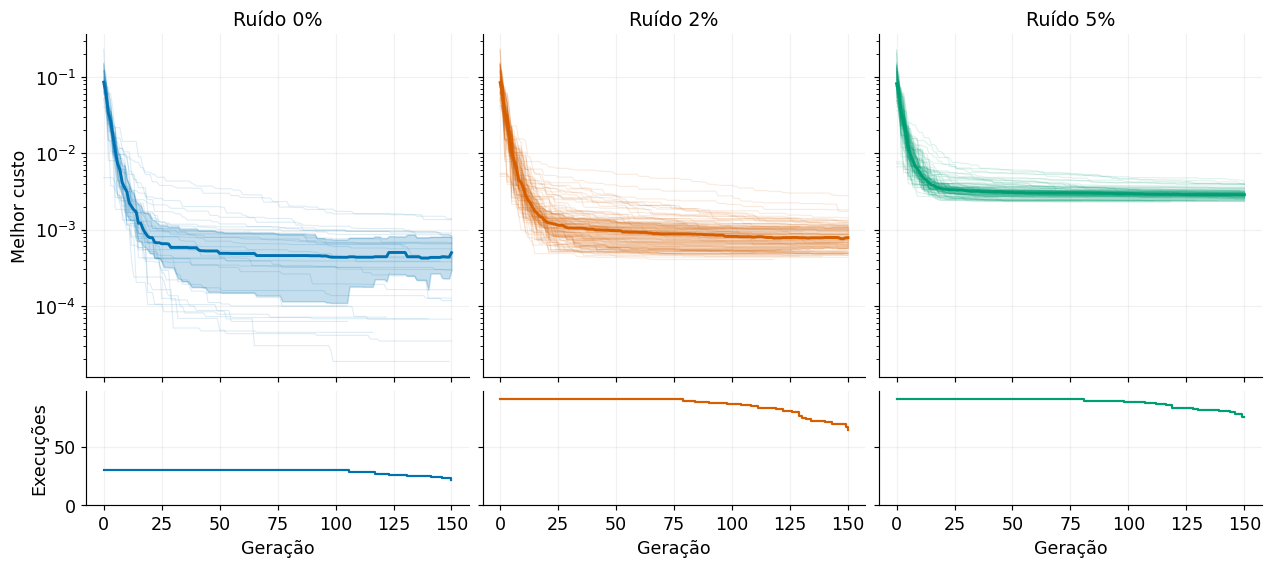

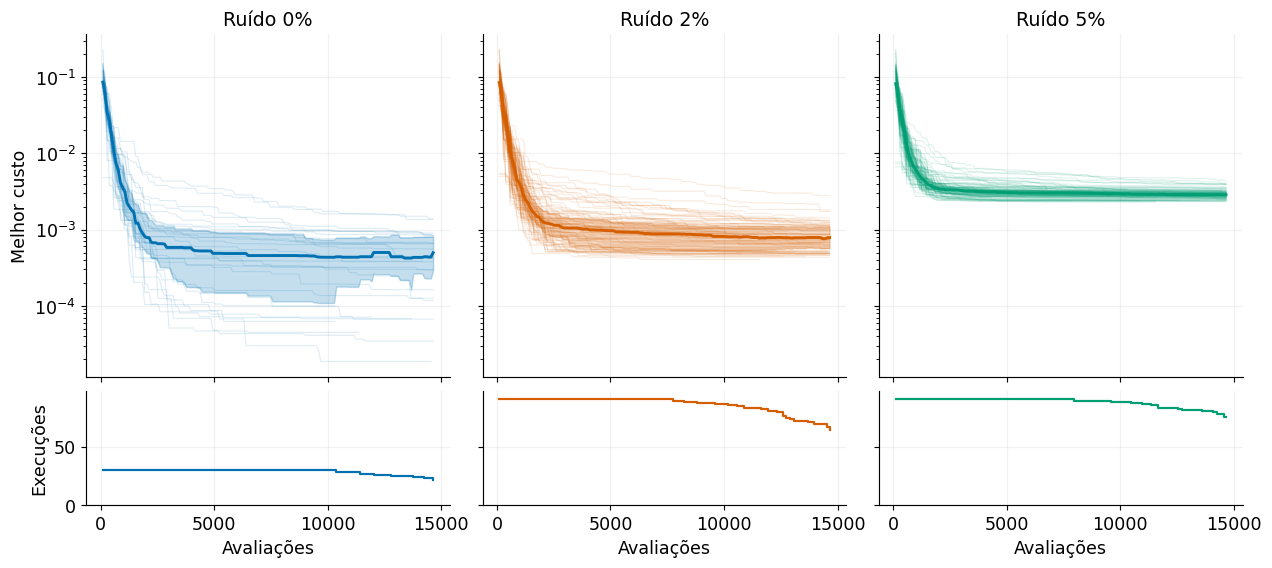

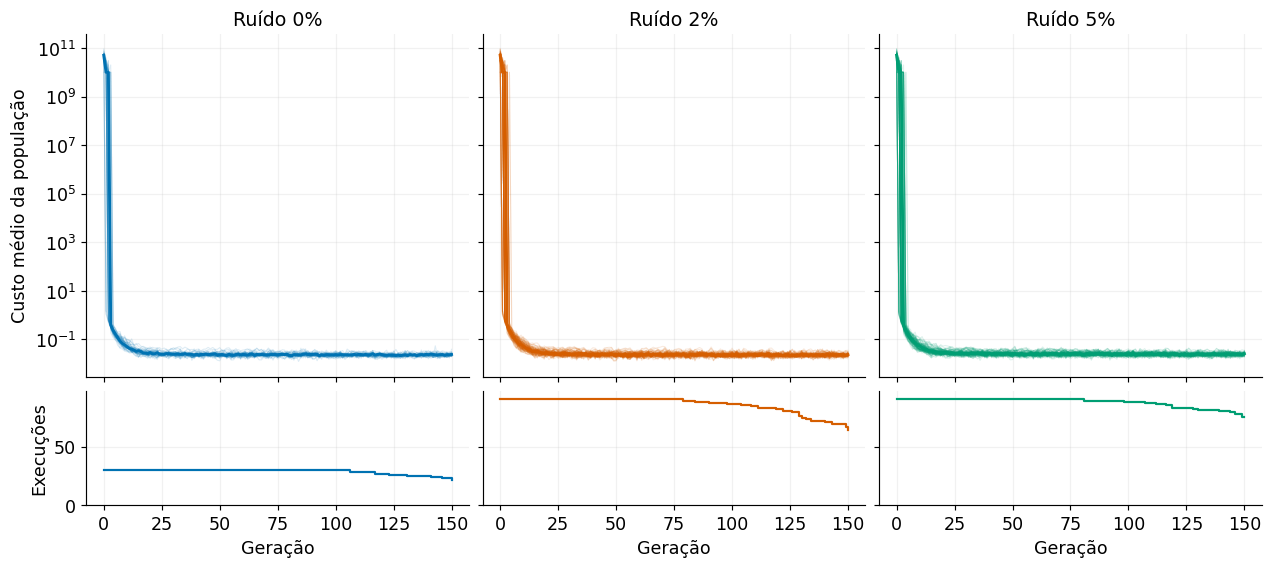

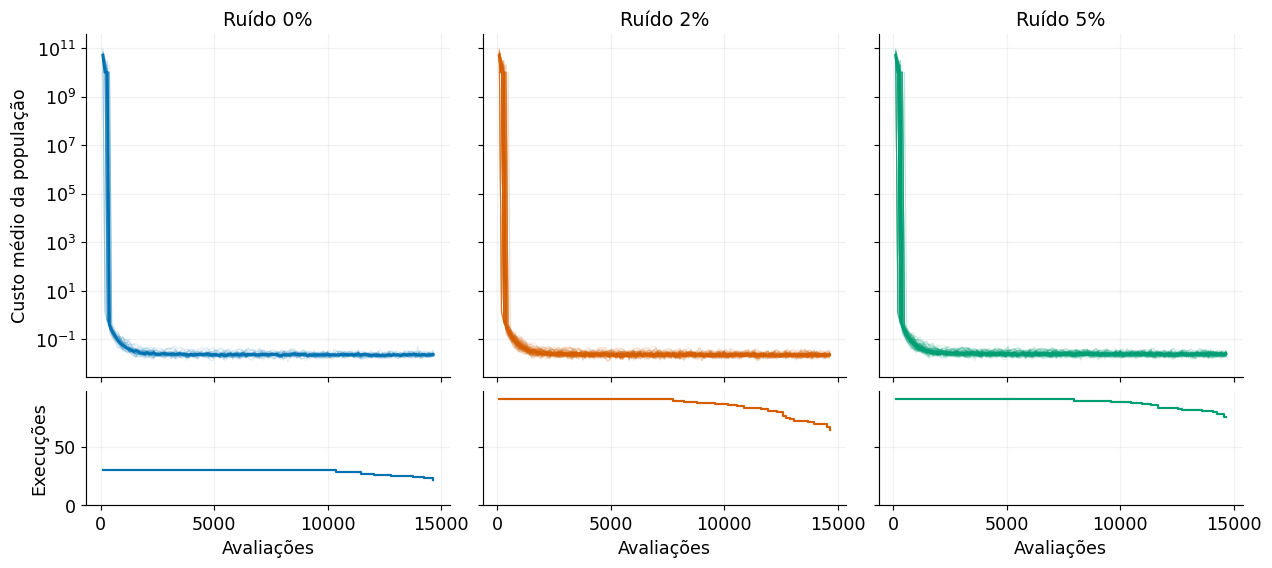

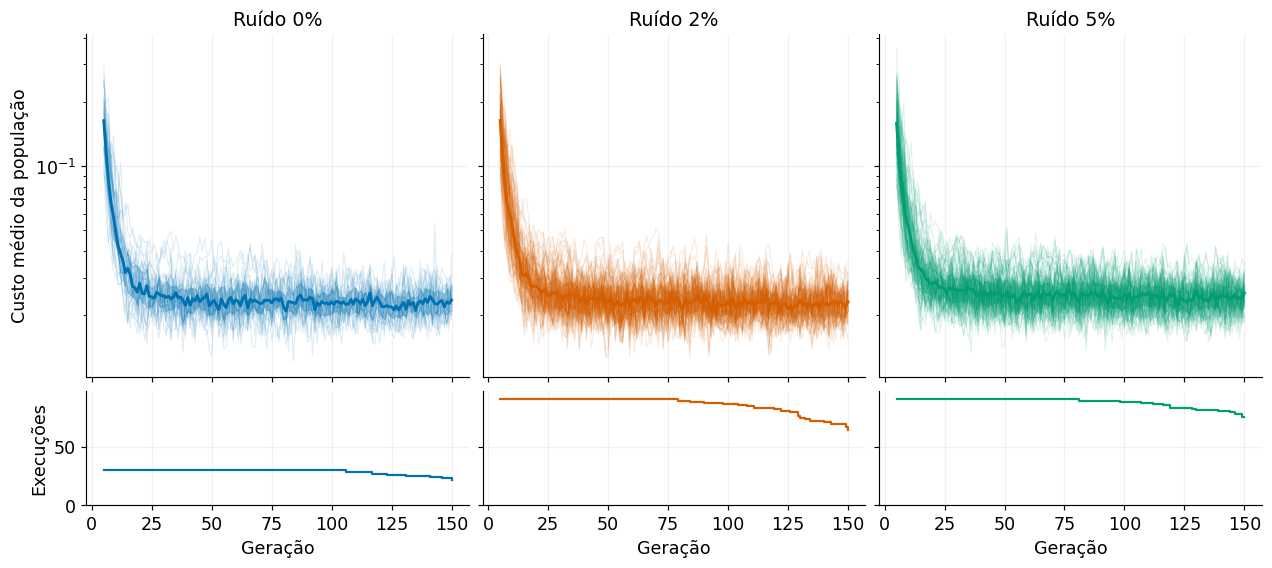

In [6]:
n_pop, elite, max_ger = (ag[k] for k in ("tamanho_populacao", "elitismo", "max_geracoes"))
orcamento_maximo = n_pop + (n_pop - elite) * max_ger
orcamento_confere = execucoes.avaliacoes.eq(n_pop + (n_pop - elite) * execucoes.geracao_final).all()
print(f"Orçamento máximo: {orcamento_maximo:,}. Identidade válida para todas as execuções: {orcamento_confere}.")

linhas_historico = []
for registro in registros:
    for geracao, (melhor, medio) in enumerate(zip(registro["historico_melhor"], registro["historico_medio"])):
        linhas_historico.append({
            **{chave: registro[chave] for chave in chaves}, "geracao": geracao,
            "melhor": melhor, "medio": medio, "sinal_penalidade": medio >= penalidade / n_pop,
        })
historicos = pd.DataFrame(linhas_historico)
if orcamento_confere:
    historicos["avaliacoes"] = n_pop + (n_pop - elite) * historicos.geracao
sinais = historicos.groupby(chaves[:2]).agg(
    registros_de_geracao=("melhor", "size"), registros_com_sinal=("sinal_penalidade", "sum"))
salvar_tabela(sinais, "sinais_penalidade_por_realizacao")
historicos.to_csv(saida / "tabelas/csv/historicos_observados.csv", index=False)

def grafico_convergencia(serie, resumo, campo, ylabel, nome, por_avaliacao=False):
    eixo = "avaliacoes" if por_avaliacao else "geracao"
    fig, eixos = plt.subplots(2, len(niveis), figsize=(12, 5.3), sharex="col", sharey="row",
                              gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
    for k, ruido in enumerate(niveis):
        ax, contagem = eixos[:, k]
        cor = cores[ruido]
        subset = serie[serie.ruido.eq(ruido)]
        perfil = resumo.loc[ruido]
        x = perfil.index.to_numpy()
        if por_avaliacao:
            x = n_pop + (n_pop - elite) * x
        for _, g in subset.groupby(["realizacao", "execucao"]):
            ax.plot(g[eixo], g[campo], color=cor, alpha=.13, lw=.75)
        ax.fill_between(x, perfil.q1, perfil.q3, color=cor, alpha=.23)
        ax.plot(x, perfil.mediana, color=cor, lw=2)
        escala_custo(ax, serie[campo])
        ax.set_title(f"Ruído {ruido:.0%}")
        ax.grid(alpha=.17)
        contagem.step(x, perfil.n, color=cor, where="post")
        contagem.set(xlabel="Avaliações" if por_avaliacao else "Geração", ylim=(0, 1.08 * resumo.n.max()))
        contagem.grid(alpha=.17)
    eixos[0, 0].set_ylabel(ylabel)
    eixos[1, 0].set_ylabel("Execuções")
    salvar_figura(fig, "convergencia", nome)


for campo, nome, ylabel in (("melhor", "melhor_custo", "Melhor custo"),
                            ("medio", "custo_medio", "Custo médio da população")):
    resumo_convergencia = historicos.groupby(["ruido", "geracao"])[campo].agg(
        n="size", mediana="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75))
    salvar_tabela(resumo_convergencia, f"tabela_convergencia_{nome}")
    grafico_convergencia(historicos, resumo_convergencia, campo, ylabel, f"convergencia_{nome}")
    if orcamento_confere:
        grafico_convergencia(historicos, resumo_convergencia, campo, ylabel,
                             f"convergencia_{nome}_por_avaliacoes", por_avaliacao=True)

# Recorte com todos os valores posteriores à última geração com sinal de penalidade.
inicio_recorte = None
ultima_com_sinal = historicos.loc[historicos.sinal_penalidade, "geracao"].max()
if pd.notna(ultima_com_sinal) and ultima_com_sinal < historicos.geracao.max():
    inicio_recorte = int(ultima_com_sinal) + 1
    trecho = historicos[historicos.geracao.ge(inicio_recorte)]
    perfil = resumo_convergencia.loc[pd.IndexSlice[:, inicio_recorte:], :]
    print(f"O recorte do custo médio começa na geração {inicio_recorte}, após o último sinal de penalidade.")
    grafico_convergencia(trecho, perfil, "medio", "Custo médio da população",
                         "convergencia_custo_medio_apos_penalidades")

## 5. Distribuição dos vencedores e disponibilidade das populações

Os histogramas abaixo usam **um vencedor por execução do AG**. Em cada parâmetro,
os intervalos são fixados pelos limites de busca. As linhas mostram o valor verdadeiro
e a mediana dos vencedores. A tabela conta apenas vencedores exatamente em um
limite, com tolerância numérica de $10^{-12}$ vezes a largura do intervalo.

O arquivo atual não contém populações inicial e final nem os custos de todos os
indivíduos. Por isso, ficam indisponíveis os histogramas da população final, a
comparação inicial–final, a diversidade residual e o acúmulo nos limites entre
todos os descendentes. Os vencedores representam saídas de otimizações
independentes, sem interpretação de distribuição posterior ou intervalo de confiança.

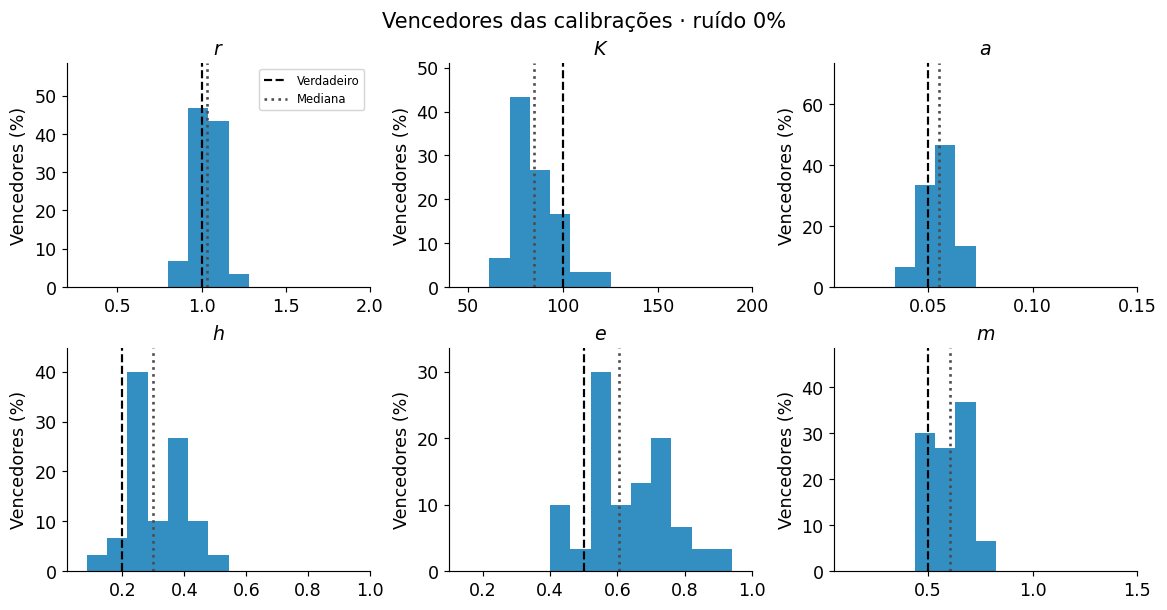

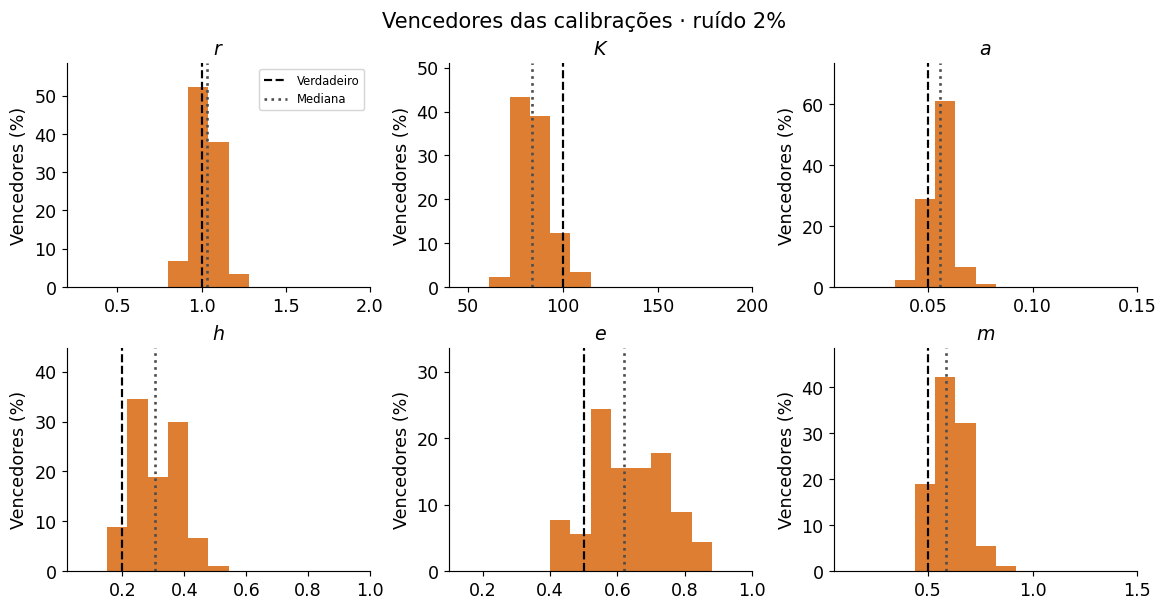

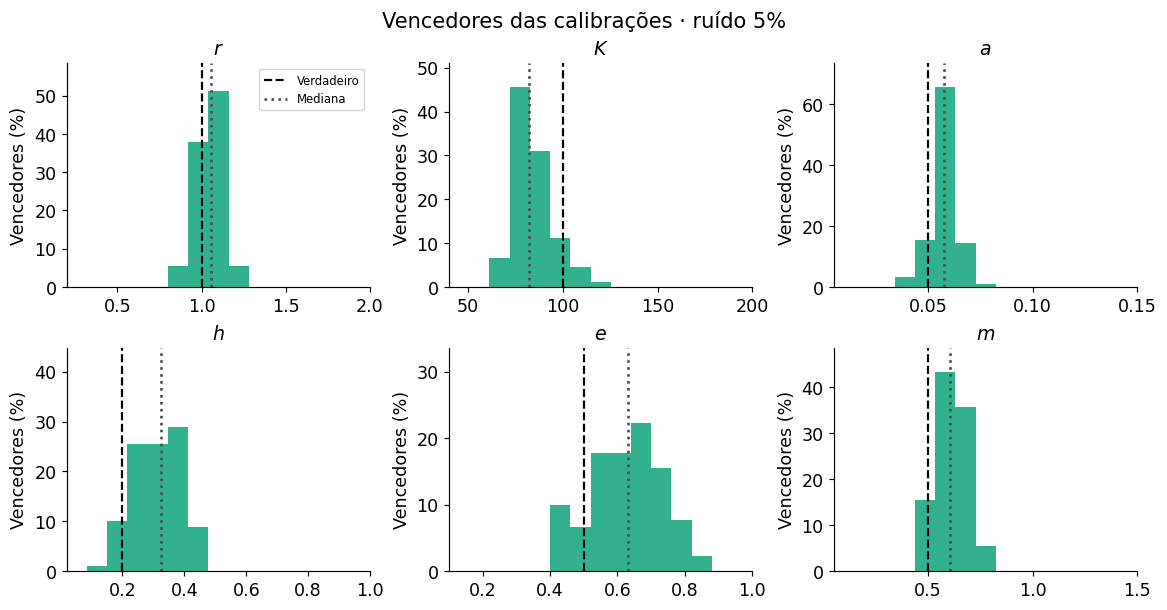

In [7]:
limites_vencedores = []
bins_genes = {p: np.linspace(lo, hi, 16) for p, (lo, hi) in zip(parametros, limites)}
max_hist = {
    p: max(100 * np.histogram(g[p], bins_genes[p])[0].max() / len(g) for g in grupos_ruido)
    for p in parametros
}
for ruido, grupo in zip(niveis, grupos_ruido):
    fig, eixos = plt.subplots(2, 3, figsize=(11, 5.7))
    for k, (p, ax) in enumerate(zip(parametros, eixos.flat)):
        lo, hi = limites[k]
        valores = grupo[p].to_numpy()
        tol = 1e-12 * (hi - lo)
        limites_vencedores.append({
            "ruido": ruido, "parametro": p, "n": len(valores),
            "limite_inferior": np.count_nonzero(np.abs(valores - lo) <= tol),
            "limite_superior": np.count_nonzero(np.abs(valores - hi) <= tol),
        })
        pesos = np.full(len(valores), 100.0 / len(valores))
        ax.hist(valores, bins=bins_genes[p], weights=pesos, color=cores[ruido], alpha=.8)
        ax.axvline(verdade[p], color="black", ls="--", label="Verdadeiro")
        ax.axvline(np.median(valores), color="#4C4C4C", ls=":", lw=1.8, label="Mediana")
        ax.set(title=rotulos[k], xlim=(lo, hi), ylim=(0, 1.12 * max_hist[p]), ylabel="Vencedores (%)")
    eixos.flat[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(f"Vencedores das calibrações · ruído {ruido:.0%}")
    salvar_figura(fig, "populacao", f"histograma_melhores_estimativas_ruido_{id_ruido(ruido)}")
limites_vencedores = pd.DataFrame(limites_vencedores)
salvar_tabela(limites_vencedores.set_index(["ruido", "parametro"]), "vencedores_nos_limites")

## 6. Influência do ruído

Para cada nível, resumimos a distribuição de $J$, o erro relativo absoluto
médio dos seis parâmetros, o NRMSE em relação à referência limpa e o custo
computacional. O intervalo interquartil de $J$ é dado pelos seus quartis
$Q_1$ e $Q_3$. Como $J$ mede a distância às observações de cada realização,
seu aumento pode refletir o ruído nos dados. O NRMSE em relação à trajetória
limpa mede a distância à trajetória geradora. A dispersão das estimativas é
mostrada pelo desvio-padrão de $\hat\theta_j/\theta_j^*$, em porcentagem.

,n,J_media,J_DP,J_mediana,J_Q1,J_Q3,ER_medio_pct,taxa_sucesso,NRMSE_ref_medio,NRMSE_obs_medio,avaliacoes_medias,tempo_medio_s,geracoes_medias
ruido,,,,,,,,,,,,,
0.00,30,0.000453,0.000380,0.000402,0.000104,0.000667,23.904440,0.033333,0.019138,0.019138,14042.133333,158.953056,143.733333
0.02,90,0.000831,0.000369,0.000744,0.000545,0.001039,23.330911,0.022222,0.019300,0.028433,13921.422222,157.680356,142.488889
0.05,90,0.002912,0.000426,0.002843,0.002616,0.003109,25.254285,0.000000,0.024242,0.055614,14241.522222,158.868290,145.788889


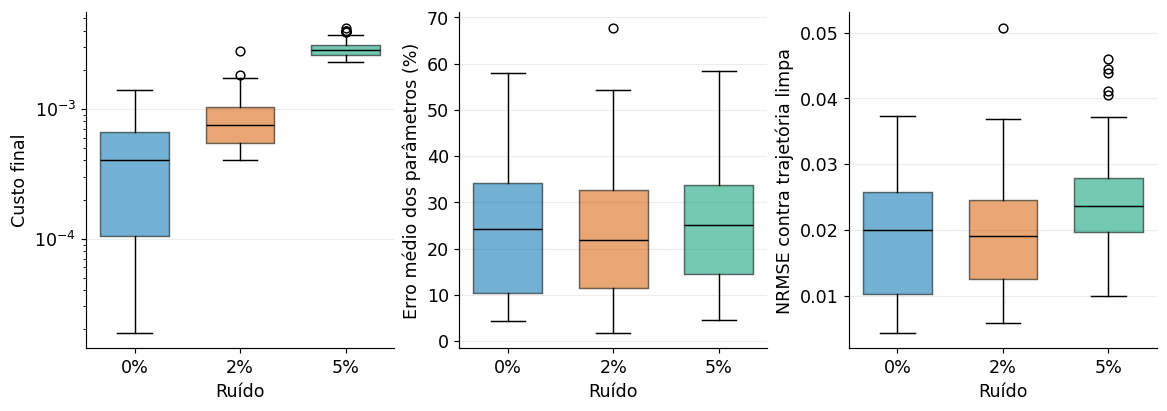

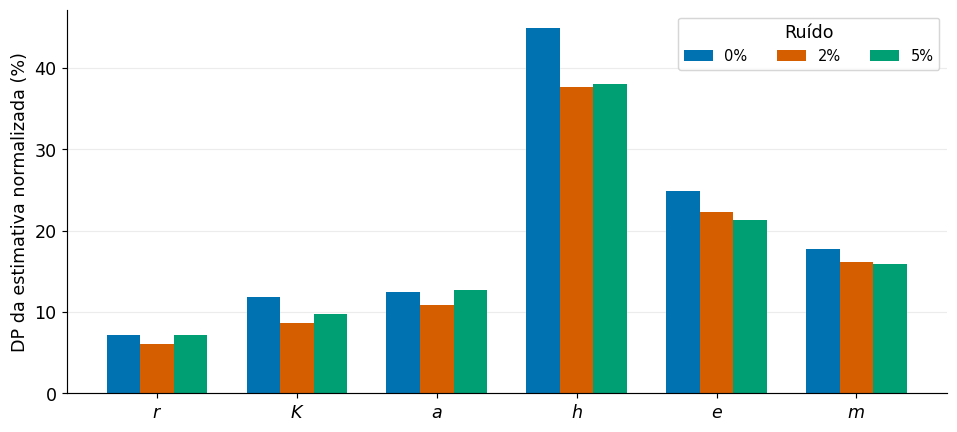

In [8]:
comparacao_ruido = execucoes.groupby("ruido").agg(
    n=("objetivo", "size"), J_media=("objetivo", "mean"), J_DP=("objetivo", "std"),
    J_mediana=("objetivo", "median"), J_Q1=("objetivo", lambda x: x.quantile(.25)),
    J_Q3=("objetivo", lambda x: x.quantile(.75)),
    ER_medio_pct=("erro_medio_pct", "mean"), taxa_sucesso=("sucesso", "mean"),
    NRMSE_ref_medio=("NRMSE_ref", "mean"), NRMSE_obs_medio=("NRMSE_obs", "mean"),
    avaliacoes_medias=("avaliacoes", "mean"), tempo_medio_s=("tempo_segundos", "mean"),
    geracoes_medias=("geracao_final", "mean"),
)
salvar_tabela(comparacao_ruido, "tabela_influencia_ruido", mostrar=True)
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, campo, titulo in zip(eixos, ("objetivo", "erro_medio_pct", "NRMSE_ref"),
                             ("Custo final", "Erro médio dos parâmetros (%)", "NRMSE contra trajetória limpa")):
    caixas_por_ruido(ax, execucoes, campo, titulo)
escala_custo(eixos[0], execucoes.objetivo)
salvar_figura(fig, "ruido", "distribuicoes_por_ruido")

fig, ax = plt.subplots(figsize=(9, 4))
for ruido, grupo, d in zip(niveis, grupos_ruido, deslocamentos):
    dp = 100 * estimativas_normalizadas.loc[grupo.index].std()
    ax.bar(posicoes + d, dp, largura, color=cores[ruido], label=rotulo_ruido(ruido))
ax.set(xticks=posicoes, xticklabels=rotulos, ylabel="DP da estimativa normalizada (%)")
ax.legend(title="Ruído", ncols=len(niveis))
ax.grid(axis="y", alpha=.24)
salvar_figura(fig, "ruido", "dispersao_estimativas_por_ruido")

## 7. Variabilidade algorítmica e observacional

As sementes do AG variam com as observações fixas dentro de cada realização.
Para cada parâmetro, resumimos a variação interna pelo
$\sqrt{(s_1^2+s_2^2+s_3^2)/3}$, em que $s_j$ é o desvio-padrão
amostral das 30 estimativas da realização $j$. A variação entre realizações é
descrita pelo desvio-padrão das três médias. O segundo indicador também
incorpora o erro de estimação dessas médias. Com três realizações por nível,
a comparação é descritiva. O protocolo usa as mesmas três sementes de dados
para 2% e 5%, escalando as mesmas perturbações entre esses níveis.

,media_realizacao_1,media_realizacao_2,media_realizacao_3,DP_dentro,DP_entre_medias,DP_dentro_pct_verdade,DP_entre_pct_verdade
r,1.037221,1.028186,1.035729,0.061182,0.004843,6.118241,0.484323
K,85.887304,84.944526,84.767490,8.755872,0.601963,8.755872,0.601963
a,0.055681,0.055527,0.055793,0.005465,0.000133,10.930939,0.266636
h,0.307321,0.312394,0.310235,0.076057,0.002546,38.028557,1.272865
e,0.625379,0.645911,0.627708,0.112184,0.011242,22.436774,2.248405
m,0.599348,0.613383,0.601039,0.081166,0.007662,16.233281,1.532326


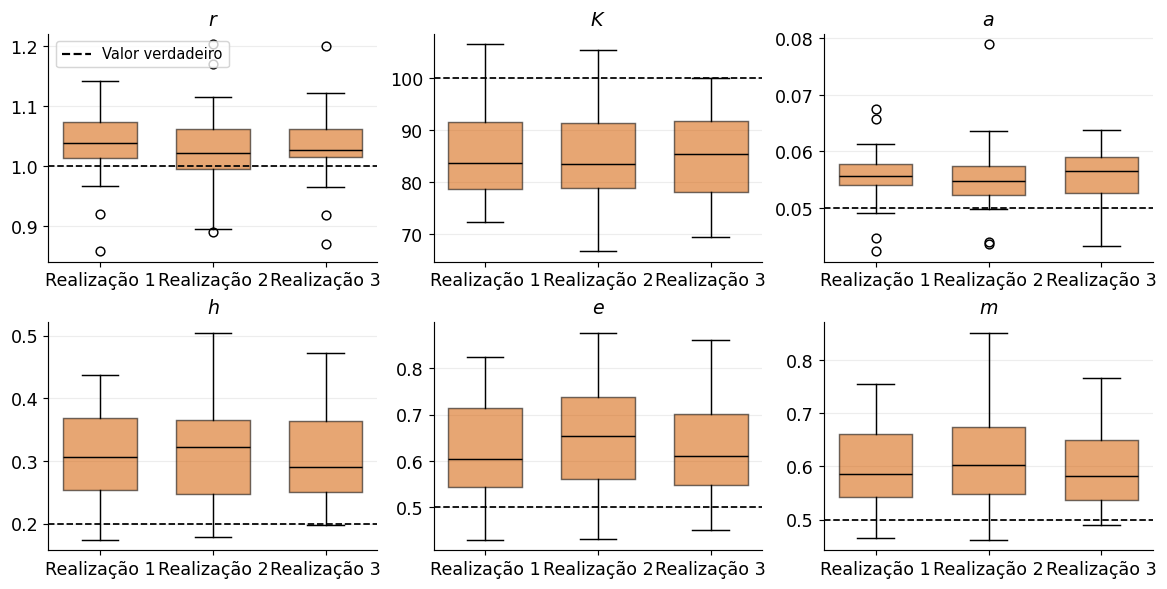

,media_realizacao_1,media_realizacao_2,media_realizacao_3,DP_dentro,DP_entre_medias,DP_dentro_pct_verdade,DP_entre_pct_verdade
r,1.074685,1.045630,1.040020,0.070756,0.018607,7.075648,1.860722
K,85.345734,84.458554,83.952699,9.783520,0.705162,9.783520,0.705162
a,0.058533,0.056768,0.057301,0.006388,0.000905,12.776127,1.810514
h,0.309796,0.310715,0.323907,0.076614,0.007895,38.306799,3.947554
e,0.602291,0.635283,0.642997,0.106326,0.021621,21.265118,4.324289
m,0.592572,0.614263,0.617507,0.079714,0.013557,15.942878,2.711386


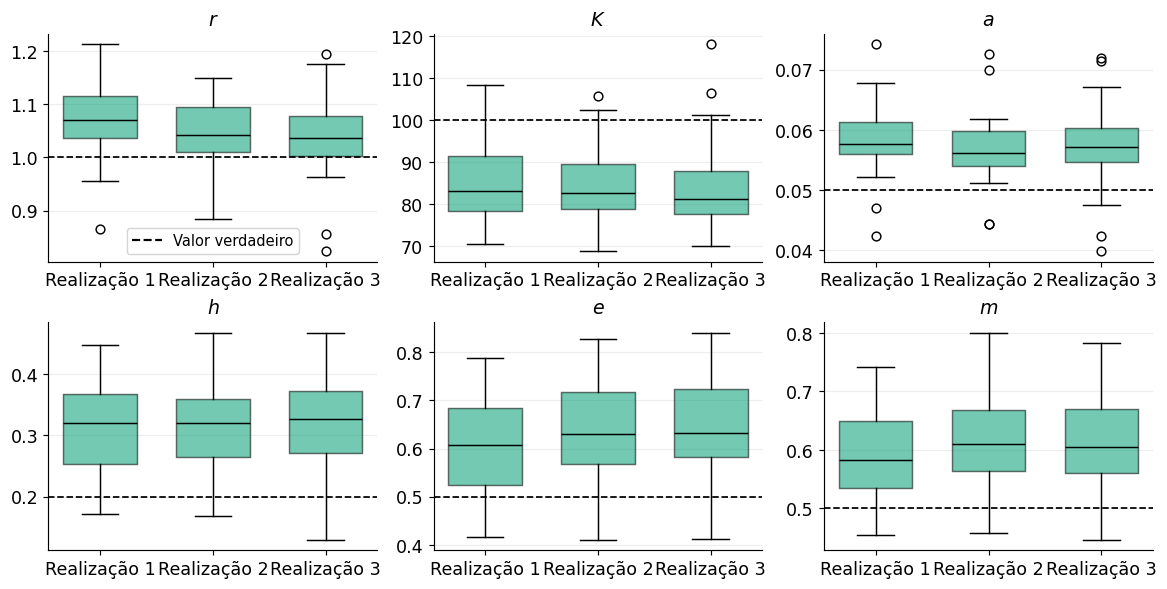

In [9]:
for ruido in (r for r in niveis if r > 0):
    subset = execucoes[execucoes.ruido.eq(ruido)]
    por_dados = subset.groupby("realizacao", sort=True)
    stats = por_dados[parametros].agg(["mean", "std", "median"]).rename(
        columns={"mean": "média", "std": "DP", "median": "mediana"}, level=1)
    stats.index = stats.index + 1
    salvar_tabela(stats, f"tabela_estimativas_por_realizacao_ruido_{id_ruido(ruido)}")
    medias = por_dados[parametros].mean()
    dentro = np.sqrt(por_dados[parametros].var().mean())
    divisao = pd.DataFrame({
        **{f"media_realizacao_{i + 1}": linha for i, linha in medias.iterrows()},
        "DP_dentro": dentro, "DP_entre_medias": medias.std(),
        "DP_dentro_pct_verdade": 100 * dentro / verdade.abs(),
        "DP_entre_pct_verdade": 100 * medias.std() / verdade.abs(),
    })
    salvar_tabela(divisao, f"tabela_variabilidade_ruido_{id_ruido(ruido)}", mostrar=True)
    perfil_estimativas([g for _, g in por_dados], [f"Realização {i + 1}" for i in por_dados.groups],
                       [cores[ruido]] * por_dados.ngroups, "variabilidade",
                       f"boxplot_por_realizacao_ruido_{id_ruido(ruido)}")

## 8. Custo computacional e critério de parada

O tempo salvo é o tempo de cada calibração, em segundos, e depende do ambiente
onde foi medido. Para inferir o motivo de parada, reproduzimos o contador de
paciência usando o histórico salvo e a comparação estrita
$J_{\mathrm{melhor}}<J_{\mathrm{ref}}-\mathrm{tol}$.
Só classificamos a execução quando o primeiro disparo reproduz a geração
salva e escolhemos a categoria “ambos os critérios” se dispararem juntos.
O orçamento teórico de 14.650 avaliações é verificado na seção de convergência.

tempo_segundos                         ... geracao_final          
                mean      median        std  ...           std  min  max
ruido                                        ...                        
0.00      158.953056  164.836158  15.332583  ...     13.567032  105  150
0.02      157.680356  164.563027  17.979751  ...     16.200461   78  150
0.05      158.868290  164.169043  15.908192  ...     12.561305   80  150

[3 rows x 15 columns]

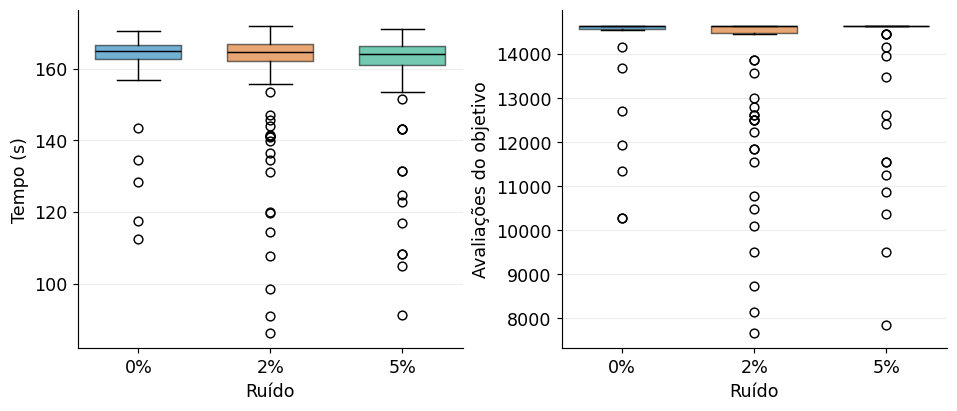

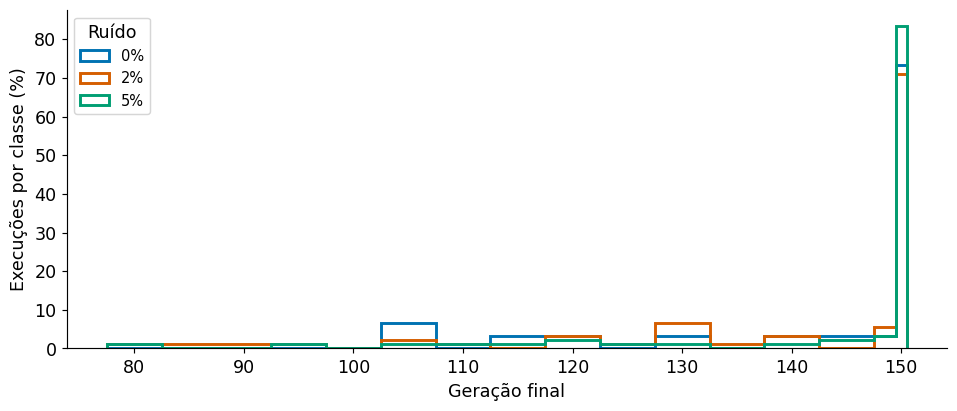

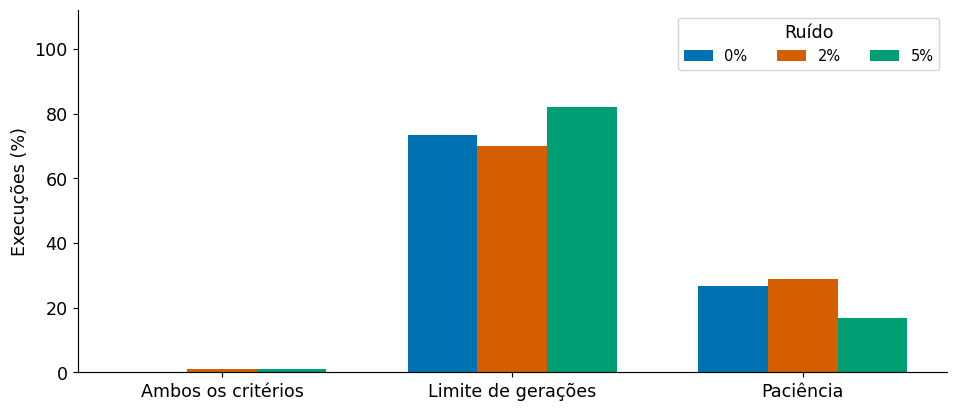

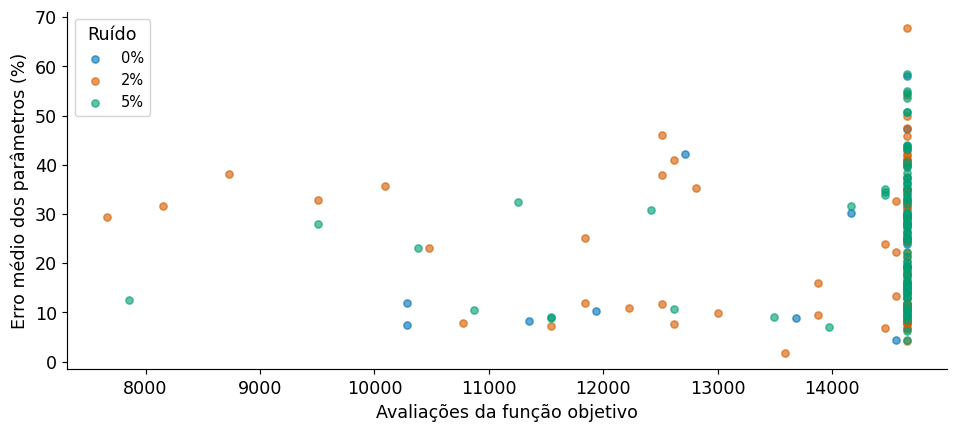

In [10]:
def inferir_parada(registro):
    referencia, consecutivas = np.inf, 0
    for geracao, melhor in enumerate(registro.historico_melhor):
        if melhor < referencia - ag["tolerancia"]:
            referencia, consecutivas = melhor, 0
        else:
            consecutivas += 1
        limite = geracao == max_ger
        paciencia = consecutivas >= ag["paciencia"]
        if limite or paciencia:
            if geracao != registro.geracao_final:
                return "Indeterminado"
            if limite and paciencia:
                return "Ambos os critérios"
            return "Limite de gerações" if limite else "Paciência"
    return "Indeterminado"


motivo_inferido = execucoes.apply(inferir_parada, axis=1)
motivo_salvo = execucoes.get("motivo_parada", pd.Series(None, index=execucoes.index, dtype=object))
execucoes["motivo_parada_analise"] = motivo_salvo.fillna(motivo_inferido)
execucoes["motivo_salvo"] = motivo_salvo.notna()
execucoes["parada_antecipada"] = execucoes.geracao_final.lt(max_ger)
campos_custo = ["tempo_segundos", "avaliacoes", "geracao_final"]
custo = execucoes.groupby("ruido")[campos_custo].agg(["mean", "median", "std", "min", "max"])
salvar_tabela(custo, "tabela_custo_computacional", mostrar=True)
paradas = pd.crosstab(execucoes.ruido, execucoes.motivo_parada_analise)
salvar_tabela(paradas.assign(antecipadas=execucoes.groupby("ruido").parada_antecipada.sum()),
              "tabela_paradas")

fig, eixos = plt.subplots(1, 2, figsize=(9, 3.8))
caixas_por_ruido(eixos[0], execucoes, "tempo_segundos", "Tempo (s)")
caixas_por_ruido(eixos[1], execucoes, "avaliacoes", "Avaliações do objetivo")
salvar_figura(fig, "custo_computacional", "boxplot_tempo_e_avaliacoes")

fig, ax = plt.subplots(figsize=(9, 3.8))
g_min = execucoes.geracao_final.min()
bins = np.r_[np.arange(g_min - .5, max_ger - .5, 5), max_ger - .5, max_ger + .5]
for ruido in niveis:
    valores = execucoes.loc[execucoes.ruido.eq(ruido), "geracao_final"]
    ax.hist(valores, bins=np.unique(bins), weights=np.full(len(valores), 100.0 / len(valores)),
            histtype="step", color=cores[ruido], lw=2, label=rotulo_ruido(ruido))
ax.set(xlabel="Geração final", ylabel="Execuções por classe (%)")
ax.legend(title="Ruído")
salvar_figura(fig, "custo_computacional", "histograma_geracoes")

fig, ax = plt.subplots(figsize=(9, 3.8))
proporcoes = 100 * paradas.div(paradas.sum(axis=1), axis=0)
for ruido, d in zip(niveis, deslocamentos):
    ax.bar(np.arange(len(proporcoes.columns)) + d, proporcoes.loc[ruido], largura,
           color=cores[ruido], label=rotulo_ruido(ruido))
ax.set(xticks=np.arange(len(proporcoes.columns)), xticklabels=proporcoes.columns,
       ylabel="Execuções (%)", ylim=(0, 112))
ax.legend(title="Ruído", ncols=len(niveis))
salvar_figura(fig, "custo_computacional", "proporcao_motivos_parada")

fig, ax = plt.subplots(figsize=(9, 4))
for ruido, grupo in execucoes.groupby("ruido"):
    ax.scatter(grupo.avaliacoes, grupo.erro_medio_pct, color=cores[ruido],
               alpha=.62, s=25, label=rotulo_ruido(ruido))
ax.set(xlabel="Avaliações da função objetivo", ylabel="Erro médio dos parâmetros (%)")
ax.legend(title="Ruído")
salvar_figura(fig, "custo_computacional", "erro_parametros_por_avaliacoes")

colunas_array = ["parametros", "historico_melhor", "historico_medio", "observacoes", "referencia"]
salvar_tabela(execucoes.drop(columns=colunas_array).set_index(chaves), "tabela_execucoes")

## 9. Correlações e dificuldade de recuperação

Pearson mede associação linear entre estimativas. Spearman é a correlação de
Pearson aplicada aos postos e captura associações monotônicas. Calculamos
ambas por nível de ruído e dentro de cada realização. Os gráficos de dispersão
usam os dois pares com maior $|r_{\mathrm{Pearson}}|$ por nível e identificam
a realização com a forma dos pontos.

No termo de predação $\frac{aNP}{1+ahN}$, a mudança em $a$ atua junto com $h$,
que regula a saturação. Na equação dos predadores, $e$ multiplica o ganho
por predação e $m$ determina a perda. Essas combinações podem produzir
ajustes parecidos em faixas restritas das trajetórias. Correlações entre
vencedores são indícios exploratórios de compensação e dependem do domínio,
dos dados e da busca do AG. Uma conclusão formal de identificabilidade
exigiria análises adicionais.

Para procurar ajustes semelhantes dentro da mesma realização, comparamos
pares no quartil inferior de $J$ cuja diferença de custo é de até 5% do
maior custo do par. Reportamos o par admissível com maior distância média
entre seus parâmetros, normalizada pelos valores verdadeiros.

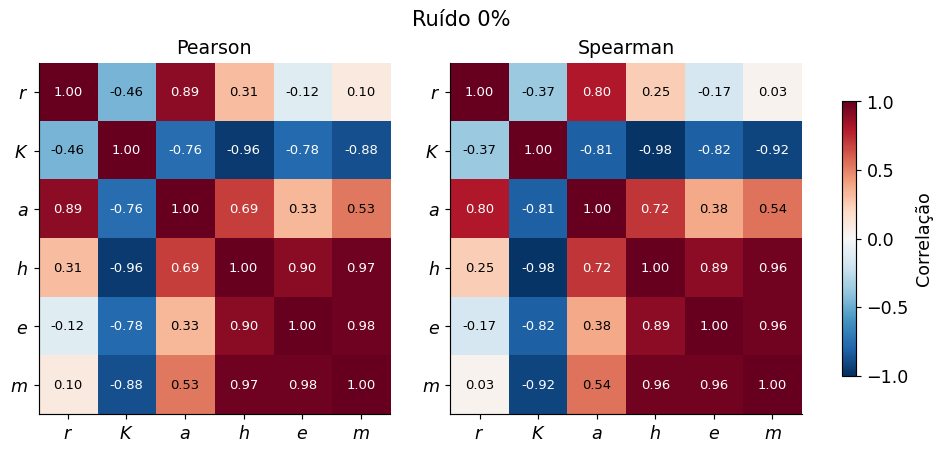

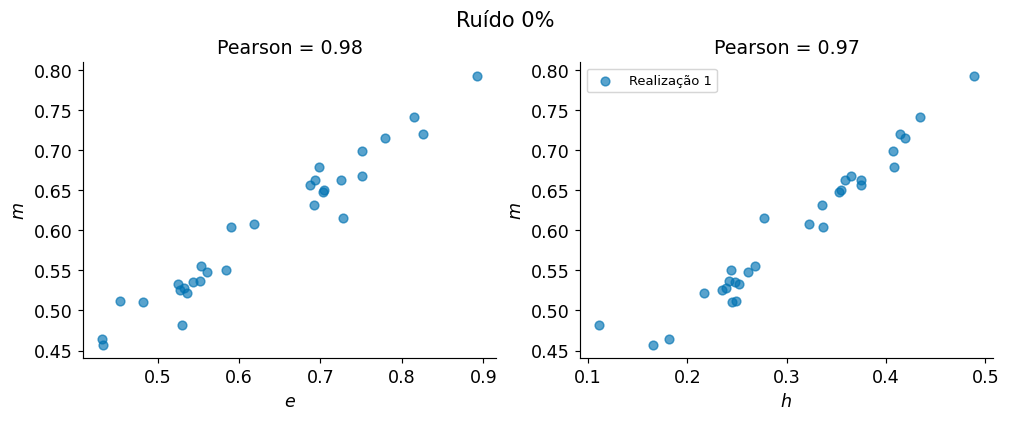

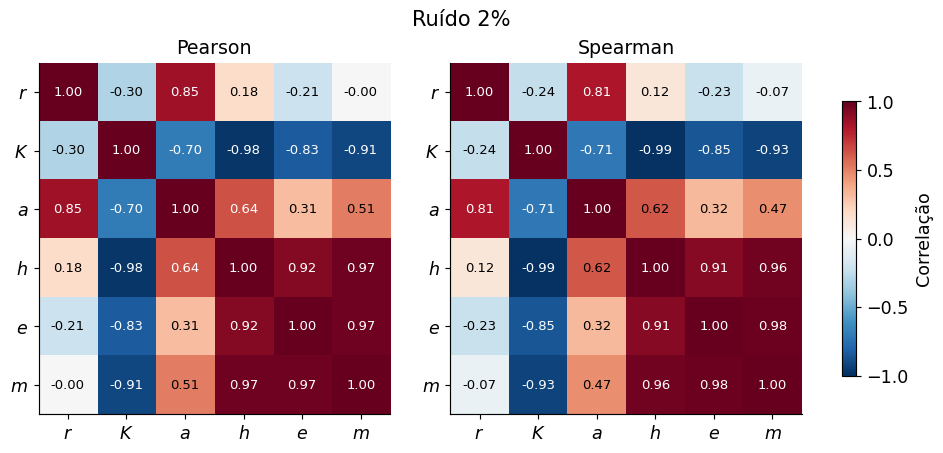

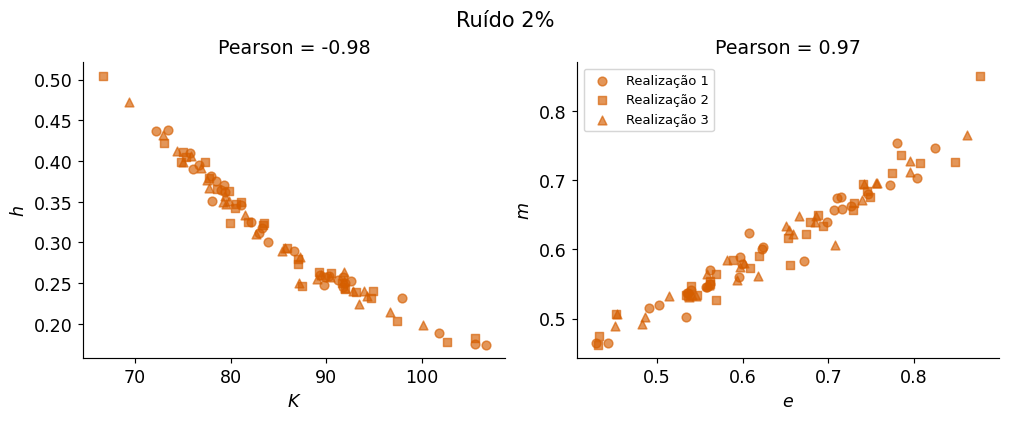

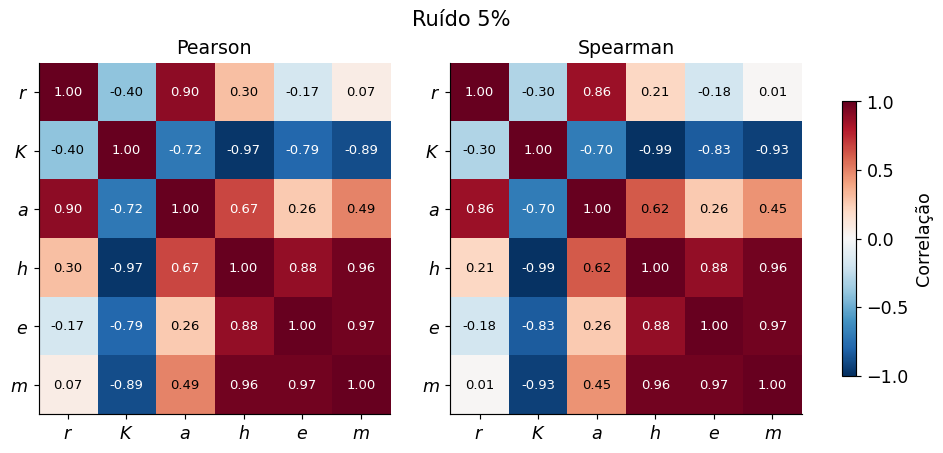

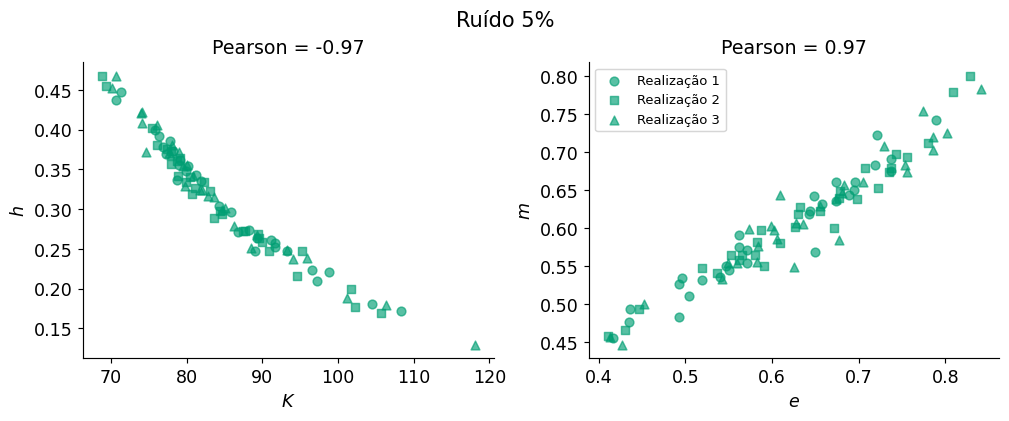

,ruido,realizacao,seed_A,seed_B,J_A,J_B,dif_J_pct,distancia_parametros_pct,ER_A_pct,ER_B_pct,r_A,K_A,a_A,h_A,e_A,m_A,r_B,K_B,a_B,h_B,e_B,m_B
0,0.00,0,3123,3125,0.000071,0.000068,4.567925,19.010638,10.234252,8.776385,0.964213,93.579389,0.048894,0.244276,0.584175,0.551108,1.038409,106.540900,0.051409,0.165238,0.432735,0.456878
1,0.02,0,3110,3120,0.000473,0.000481,1.562761,16.817763,7.910037,10.916637,1.085892,101.759109,0.055203,0.188940,0.428844,0.465275,1.012837,91.726871,0.052372,0.257269,0.562202,0.550624
2,0.02,1,3120,3125,0.000509,0.000486,4.440604,17.523210,12.885640,8.236397,1.033335,89.266771,0.054011,0.264315,0.561206,0.554135,1.070597,102.583475,0.053731,0.178085,0.431294,0.461932
3,0.02,2,3110,3112,0.000490,0.000498,1.645032,6.884115,4.241201,8.574106,1.044366,96.682453,0.053375,0.214830,0.485362,0.503007,1.019704,91.934327,0.052245,0.243850,0.540913,0.534057
4,0.05,0,3120,3125,0.002420,0.002327,3.848571,17.603696,10.926624,9.930667,1.030257,91.652647,0.053368,0.257023,0.550464,0.544237,1.092766,104.454712,0.055054,0.180121,0.415898,0.455073
5,0.05,1,3110,3123,0.002411,0.002415,0.157958,24.386518,10.738143,14.419744,1.113644,102.270908,0.056424,0.176736,0.410052,0.458381,0.985093,89.385524,0.051157,0.268152,0.609562,0.580555
6,0.05,2,3118,3125,0.002866,0.002722,4.996747,30.180191,15.751304,14.428888,1.067794,86.290059,0.056954,0.279085,0.548819,0.554023,0.972495,118.120196,0.047586,0.129141,0.426799,0.445980


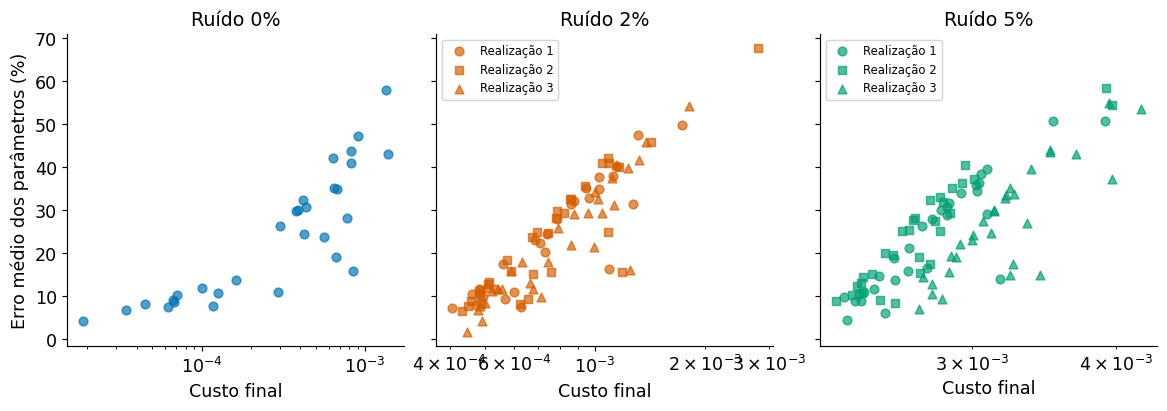

In [11]:
def pares_ordenados(matriz):
    return sorted(
        ((p, q, matriz.at[p, q]) for i, p in enumerate(parametros)
         for q in parametros[i + 1:] if np.isfinite(matriz.at[p, q])),
        key=lambda item: -abs(item[2]),
    )


def heatmaps(subset, titulo, nome):
    matrizes = {m: subset[parametros].corr(method=m) for m in ("pearson", "spearman")}
    fig, eixos = plt.subplots(1, 2, figsize=(9.1, 4.2))
    for metodo, ax in zip(matrizes, eixos):
        matriz = matrizes[metodo]
        salvar_tabela(matriz, f"{nome}_{metodo}")
        mapa = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
        for i, j in np.ndindex(matriz.shape):
            v = matriz.iloc[i, j]
            ax.text(j, i, f"{v:.2f}" if np.isfinite(v) else "—", ha="center", va="center",
                    color="white" if abs(v) > .62 else "black", fontsize=9)
        ax.set(title=metodo.capitalize(), xticks=posicoes, yticks=posicoes,
               xticklabels=rotulos, yticklabels=rotulos)
    fig.colorbar(mapa, ax=eixos, shrink=.78, label="Correlação")
    fig.suptitle(titulo)
    salvar_figura(fig, "correlacao", nome, mostrar="realizacao" not in nome)
    return matrizes


pares_destaque = []
for ruido, subset in execucoes.groupby("ruido"):
    prefixo = f"correlacao_parametros_ruido_{id_ruido(ruido)}"
    matrizes = heatmaps(subset, f"Ruído {ruido:.0%}", prefixo)
    pares = pares_ordenados(matrizes["pearson"])[:2]
    if pares:
        fig, eixos = plt.subplots(1, len(pares), figsize=(9.5, 3.9), squeeze=False)
        for ax, (p, q, rho) in zip(eixos.flat, pares):
            pares_destaque.append({"ruido": ruido, "p": p, "q": q, "pearson": rho,
                                   "spearman": matrizes["spearman"].at[p, q]})
            for j, g in subset.groupby("realizacao"):
                ax.scatter(g[p], g[q], marker=("o", "s", "^")[j % 3], color=cores[ruido],
                           alpha=.65, label=f"Realização {j + 1}")
            ax.set(xlabel=f"${p}$", ylabel=f"${q}$", title=f"Pearson = {rho:.2f}")
        eixos.flat[-1].legend(fontsize=9)
        fig.suptitle(f"Ruído {ruido:.0%}")
        salvar_figura(fig, "correlacao", f"pares_correlacionados_ruido_{id_ruido(ruido)}")
    for j, g in subset.groupby("realizacao"):
        heatmaps(g, f"Ruído {ruido:.0%} · realização {j + 1}",
                 f"{prefixo}_realizacao_{j + 1:02d}")

pares_destaque = pd.DataFrame(pares_destaque)
salvar_tabela(pares_destaque, "tabela_pares_correlacionados")
pares_custo = []
bom_ajuste = pd.Series(False, index=execucoes.index)
for (ruido, j), g in execucoes.groupby(chaves[:2]):
    validos = g[g.simulacao_valida & ~g.penalidade_final]
    melhores = validos[validos.objetivo <= validos.objetivo.quantile(.25)]
    bom_ajuste.loc[melhores.index] = True
    pares = []
    for k, i in enumerate(melhores.index):
        for l in melhores.index[k + 1:]:
            ji, jl = execucoes.loc[[i, l], "objetivo"]
            maior = max(ji, jl)
            diferenca = abs(ji - jl) / maior if maior else 0.0
            if diferenca <= .05:
                distancia = 100 * (estimativas_normalizadas.loc[i] - estimativas_normalizadas.loc[l]).abs().mean()
                pares.append((distancia, i, l, diferenca))
    if pares:
        distancia, i, l, diferenca = max(pares, key=lambda par: par[0])
        a, b = execucoes.loc[i], execucoes.loc[l]
        pares_custo.append({
            "ruido": ruido, "realizacao": j, "seed_A": a.seed, "seed_B": b.seed,
            "J_A": a.objetivo, "J_B": b.objetivo, "dif_J_pct": diferenca * 100,
            "distancia_parametros_pct": distancia, "ER_A_pct": a.erro_medio_pct,
            "ER_B_pct": b.erro_medio_pct,
            **{f"{p}_A": a[p] for p in parametros}, **{f"{p}_B": b[p] for p in parametros},
        })
pares_custo = pd.DataFrame(pares_custo)
salvar_tabela(pares_custo, "tabela_pares_com_custos_proximos", mostrar=True)

fig, eixos = plt.subplots(1, len(niveis), figsize=(11, 3.8), sharey=True, squeeze=False)
for ax, (ruido, g) in zip(eixos.flat, execucoes.groupby("ruido")):
    for j, sub in g.groupby("realizacao"):
        ax.scatter(sub.objetivo, sub.erro_medio_pct, marker=("o", "s", "^")[j % 3],
                   color=cores[ruido], alpha=.68, label=f"Realização {j + 1}")
    if g.objetivo.gt(0).all():
        ax.set_xscale("log")
    ax.set(xlabel="Custo final", title=f"Ruído {ruido:.0%}")
    if g.realizacao.nunique() > 1:
        ax.legend(fontsize=8)
eixos.flat[0].set_ylabel("Erro médio dos parâmetros (%)")
salvar_figura(fig, "correlacao", "custo_final_vs_erro_parametros")

## 10. SHAP para a função objetivo

A implementação em `shap_objetivo.py` percorre os 64 subconjuntos dos seis
parâmetros. Para um subconjunto $S$, $v(S)$ é a média do objetivo calculado
com os valores estimados nas posições de $S$ e preenchimento das demais
posições com cada um dos oito vetores de referência. Os vetores vêm de um
hipercubo latino com semente 2026 na faixa de $\pm10\%$ dos parâmetros
verdadeiros, limitada ao domínio de busca. O valor-base $v(\varnothing)$
é calculado separadamente para as observações de cada realização. A
aditividade esperada é $J(\hat\theta)=v(\varnothing)+\sum_j\phi_j$.

O JSON não contém os valores de $\phi$. A saída salva no notebook de
calibração contém um gráfico, sem a tabela de contribuições. Quando houver
uma exportação da variável `tabela_shap` do notebook de calibração, aponte
`arquivo_shap` para esse CSV. Ele deve conter `ruido`, `realizacao`,
`execucao`, `objetivo`, `objetivo_referencia` e as seis colunas
`r,K,a,h,e,m`, com a numeração original das realizações a partir de zero.
A célula valida as chaves, os custos, a referência e a aditividade.
A validação do valor-base requer só oito integrações, compartilhadas por
todas as realizações.

A importância de um parâmetro é a média de $|\phi_j|$. Agrupamos primeiro
por realização, como no gráfico original, e usamos o mesmo peso para as
realizações ao agregar por ruído. A importância global dá o mesmo peso
a cada calibração, de modo que níveis com mais execuções têm maior peso.
As contribuições explicam $J$ em relação à referência especificada.
Erro de estimação, sensibilidade local, causalidade e identificabilidade
exigem outras medidas.

In [12]:
resumo_shap = None
if not arquivo_shap.is_file():
    display(Markdown("**SHAP individual indisponível.** A tabela de contribuições ainda não foi exportada."))
else:
    colunas_shap = chaves + ["objetivo", "objetivo_referencia"] + parametros
    shap = pd.read_csv(arquivo_shap, usecols=colunas_shap)
    if not np.isfinite(shap[colunas_shap]).all().all():
        raise ValueError("A tabela SHAP contém valores ausentes ou não finitos.")
    shap = shap.rename(columns={"objetivo": "J_SHAP", **{p: f"phi_{p}" for p in parametros}})
    ids = execucoes[chaves + ["objetivo", "seed"] + parametros]
    shap = ids.merge(shap, on=chaves, how="outer", validate="one_to_one", indicator=True)
    if not shap["_merge"].eq("both").all():
        raise ValueError("As chaves do CSV SHAP não correspondem às calibrações salvas.")
    phi = [f"phi_{p}" for p in parametros]
    np.testing.assert_allclose(shap.J_SHAP, shap.objetivo, rtol=1e-9, atol=1e-12)
    np.testing.assert_allclose(shap.objetivo_referencia + shap[phi].sum(axis=1),
                               shap.J_SHAP, rtol=1e-9, atol=1e-12)

    margem = .10 * verdade.abs().to_numpy()
    referencia_shap = qmc.scale(qmc.LatinHypercube(d=len(parametros), seed=2026).random(n=8),
                                np.maximum(limites[:, 0], verdade - margem),
                                np.minimum(limites[:, 1], verdade + margem))
    simulacoes_shap = [simular(vetor) for vetor in referencia_shap]
    if any(s is None for s in simulacoes_shap):
        raise ValueError("Simulação inválida na referência SHAP.")
    for chave, g in shap.groupby(chaves[:2]):
        observacoes = grupos.get_group(chave).observacoes.iloc[0]
        base = np.mean([custo_simulado(s, observacoes) for s in simulacoes_shap])
        np.testing.assert_allclose(g.objetivo_referencia, base, rtol=1e-9, atol=1e-12)

    importancias = shap.set_index(chaves)[phi].abs().groupby(level=[0, 1]).mean()
    importancias.columns = parametros
    resumo_shap = importancias.groupby(level=0).mean()
    global_shap = shap[phi].abs().mean().set_axis(parametros).sort_values()
    tabela_shap = resumo_shap.T.assign(global_por_execucao=global_shap)
    salvar_tabela(importancias, "tabela_shap_por_realizacao")
    salvar_tabela(tabela_shap, "tabela_shap_importancia", mostrar=True)
    erro_aditivo = (shap.objetivo_referencia + shap[phi].sum(axis=1) - shap.J_SHAP).abs().max()
    print(f"Maior resíduo de aditividade: {erro_aditivo:.3g}")

    fig, ax = plt.subplots(figsize=(8.4, 3.7))
    ax.barh([f"${p}$" for p in global_shap.index], global_shap, color="#5B6573")
    ax.set_xlabel("Média global de |SHAP|")
    salvar_figura(fig, "shap", "shap_importancia_global")

    fig, ax = plt.subplots(figsize=(9.3, 4))
    for r, d in zip(niveis, deslocamentos):
        ax.bar(posicoes + d, resumo_shap.loc[r], largura, color=cores[r], label=rotulo_ruido(r))
    ax.set(xticks=posicoes, xticklabels=rotulos, ylabel="Média de |SHAP|")
    ax.legend(title="Ruído")
    salvar_figura(fig, "shap", "shap_importancia_por_ruido")

    fig, ax = plt.subplots(figsize=(9.3, 4.3))
    for r, d in zip(niveis, deslocamentos):
        g = shap[shap.ruido.eq(r)]
        colorir_caixas(ax, [g[c] for c in phi], posicoes + d, [cores[r]] * len(phi), largura * .86)
    ax.axhline(0, color="black", lw=.9)
    ax.set(xticks=posicoes, xticklabels=rotulos, ylabel="Valor SHAP")
    ax.legend(handles=legenda_ruido, title="Ruído")
    salvar_figura(fig, "shap", "shap_boxplots")

    fig, ax = plt.subplots(figsize=(9.2, 4.8))
    ordem_shap = global_shap.index
    for linha, p in enumerate(ordem_shap):
        # Distribui verticalmente pontos vizinhos sem alterar as contribuições no eixo x.
        valores = shap[f"phi_{p}"].to_numpy()
        arestas = np.linspace(shap[phi].to_numpy().min(), shap[phi].to_numpy().max(), 55)
        caixas = np.digitize(valores, arestas)
        desvios = np.zeros(len(valores))
        for caixa in np.unique(caixas):
            indices = np.flatnonzero(caixas == caixa)
            desvios[indices] = np.linspace(-.3, .3, len(indices)) if len(indices) > 1 else 0
        cor_gene = (shap[p] - shap[p].min()) / max(shap[p].max() - shap[p].min(), 1e-15)
        pontos = ax.scatter(valores, linha + desvios, c=cor_gene, s=13, cmap="viridis",
                            vmin=0, vmax=1, alpha=.76, edgecolors="none")
    fig.colorbar(pontos, ax=ax, label="Valor estimado (mínimo a máximo por parâmetro)")
    ax.axvline(0, color="black", lw=.9)
    ax.set(yticks=posicoes, yticklabels=[f"${p}$" for p in ordem_shap], xlabel="Valor SHAP")
    salvar_figura(fig, "shap", "shap_beeswarm")

    fig, eixos = plt.subplots(2, 3, figsize=(11, 5.5))
    for p, ax in zip(parametros, eixos.flat):
        for r, g in shap.groupby("ruido"):
            ax.scatter(g[p], g[f"phi_{p}"], color=cores[r], s=14, alpha=.6, label=rotulo_ruido(r))
        ax.axhline(0, color="black", lw=.75)
        ax.set(xlabel=f"${p}$ estimado", ylabel="Valor SHAP")
    eixos.flat[0].legend(title="Ruído", fontsize=8)
    salvar_figura(fig, "shap", "shap_dependencia")

    for r, j in representativas.items():
        g = shap[shap.ruido.eq(r) & shap.realizacao.eq(j)]
        linha = g.sort_values(["J_SHAP", "seed"]).iloc[0]
        ordem = linha[phi].astype(float).abs().sort_values(ascending=False).index
        valores = linha[ordem].to_numpy(dtype=float)
        base = linha.objetivo_referencia
        pontos_acumulados = base + np.r_[0, np.cumsum(valores)]
        fig, ax = plt.subplots(figsize=(9, 4))
        for i, valor in enumerate(valores):
            ax.barh(i, abs(valor), left=min(pontos_acumulados[i:i + 2]), height=.65,
                    color="#D55E00" if valor >= 0 else "#0072B2")
            if i < len(valores) - 1:
                ax.plot([pontos_acumulados[i + 1]] * 2, [i + .32, i + .68], color="#777777", lw=.8)
        ax.axvline(base, color="#555555", ls="--", label=f"Base = {base:.3g}")
        ax.axvline(linha.J_SHAP, color="black", ls=":", label=f"Custo = {linha.J_SHAP:.3g}")
        ax.invert_yaxis()
        ax.set(yticks=posicoes, yticklabels=[f"${c[4:]}$" for c in ordem],
               xlabel="Contribuição acumulada para J",
               title=f"Ruído {r:.0%} · realização {j + 1} · semente {int(linha.seed)}")
        ax.legend(fontsize=9)
        salvar_figura(fig, "shap", f"shap_waterfall_ruido_{id_ruido(r)}")

**SHAP individual indisponível.** A tabela de contribuições ainda não foi exportada.

## 11. Síntese para a apresentação

A síntese é gerada a partir das tabelas e dos históricos desta execução.
Para descrever a convergência até a geração 50, comparamos as mesmas
execuções que chegaram à geração 50, usando o declínio percentual em relação
à geração inicial. A parada antecipada indica estagnação segundo a regra de
paciência configurada. Ela não determina se o vetor encontrado é um ótimo global.

In [13]:
def pt(valor, casas=1):
    return f"{valor:.{casas}f}".replace(".", ",")


linhas = ["# Síntese da calibração de Rosenzweig–MacArthur", "",
          f"Foram analisadas {len(execucoes)} calibrações em {len(protocolo_observado)} realizações dos dados.", "",
          "## Recuperação e ajuste", ""]
for r, s in resumos.items():
    melhor, pior = s.ER_medio_pct.idxmin(), s.ER_medio_pct.idxmax()
    g = execucoes[execucoes.ruido.eq(r)]
    j = representativas[r]
    linhas.append(
        f"- **Ruído {rotulo_ruido(r)}**. Menor erro relativo absoluto médio para `{melhor}` "
        f"({pt(s.at[melhor, 'ER_medio_pct'])}%) e maior para `{pior}` "
        f"({pt(s.at[pior, 'ER_medio_pct'])}%). Erro médio dos seis parâmetros de "
        f"{pt(g.erro_medio_pct.mean())}% e NRMSE médio contra a trajetória limpa de "
        f"{pt(100 * g.NRMSE_ref.mean(), 2)}%. {int(g.sucesso.sum())} de {len(g)} "
        f"execuções cumpriram o critério de recuperação. A realização {j + 1} é a representativa."
    )
menor_custo_sem_recuperacao = bom_ajuste & ~execucoes.sucesso
if menor_custo_sem_recuperacao.any():
    linhas.append(
        f"- {int(menor_custo_sem_recuperacao.sum())} das {int(bom_ajuste.sum())} execuções no "
        "quartil de menor custo de suas respectivas realizações ficaram fora da tolerância "
        "em pelo menos um parâmetro."
    )
ruidosos = execucoes[execucoes.ruido.gt(0)]
abaixo = ruidosos.J_abaixo_verdadeiro
linhas.extend([
    f"- Em dados ruidosos, {int(abaixo.sum())} de {len(ruidosos)} estimativas obtiveram "
    f"custo menor que o vetor verdadeiro. Destas, {int((abaixo & ~ruidosos.sucesso).sum())} "
    "ficaram fora da tolerância de recuperação em pelo menos um parâmetro.",
    "- O custo final mede o ajuste às observações de cada realização. A comparação "
    "com a trajetória limpa e a recuperação dos parâmetros complementam esse indicador.",
    "", "## Convergência e custo computacional", "",
])
marco = min(50, max_ger)
inicio = historicos[historicos.geracao.eq(0)].set_index(chaves)
fim = historicos[historicos.geracao.eq(marco)].set_index(chaves)
for r, g in execucoes.groupby("ruido"):
    grupo_fim = fim[fim.index.get_level_values("ruido") == r]
    grupo_inicio = inicio.loc[grupo_fim.index]
    comeco = grupo_inicio[["melhor", "medio"]].replace(0, np.nan)
    reducao = 100 * (1 - grupo_fim[["melhor", "medio"]] / comeco).median()
    linhas.append(
        f"- **Ruído {rotulo_ruido(r)}**. Entre a geração inicial e a geração {marco}, "
        f"a queda mediana do melhor custo foi {pt(reducao['melhor'])}% nas "
        f"{len(grupo_fim)} execuções que chegaram a esse ponto. "
        f"O custo médio mediano da população passou de {grupo_inicio.medio.median():.2g} "
        f"para {grupo_fim.medio.median():.2g}. "
        f"Houve {int(g.parada_antecipada.sum())} paradas antecipadas. "
        f"O tempo médio foi {pt(g.tempo_segundos.mean())} s, com "
        f"{pt(g.avaliacoes.mean(), 0)} avaliações e {pt(g.geracao_final.mean())} gerações em média."
    )
por_execucao_penalidade = historicos.groupby(chaves).sinal_penalidade.any()
linhas.extend([
    f"- O máximo teórico foi de {orcamento_maximo} avaliações. A fórmula por geração "
    f"{'reproduziu todos os' if orcamento_confere else 'divergiu de pelo menos um dos'} totais salvos. "
    f"{int(por_execucao_penalidade.sum())} execuções tiveram pelo menos uma geração cujo "
    "custo médio sinaliza penalidade. "
    f"{int((~execucoes.simulacao_valida).sum())} trajetórias vencedoras foram inválidas na "
    f"reconstrução e {int((~execucoes.J_igual_salvo).sum())} custos recalculados divergiram dos salvos.",
    "", "## Compensações e limitações", "",
])
for r, g in pares_destaque.groupby("ruido"):
    primeiro = g.iloc[0]
    linhas.append(
        f"- **Ruído {rotulo_ruido(r)}**. A maior correlação de Pearson em módulo foi entre "
        f"`{primeiro.p}` e `{primeiro.q}` (r = {pt(primeiro.pearson, 2)}, "
        f"Spearman = {pt(primeiro.spearman, 2)}). As matrizes por realização permitem consultar "
        "as associações com os dados fixos."
    )
if not pares_custo.empty:
    par = pares_custo.loc[pares_custo.distancia_parametros_pct.idxmax()]
    linhas.append(
        f"- No ruído de {rotulo_ruido(par.ruido)}, realização {int(par.realizacao) + 1}, "
        f"as sementes {int(par.seed_A)} e {int(par.seed_B)} produziram custos com diferença relativa "
        f"de {pt(par.dif_J_pct, 2)}% e vetores separados em média por "
        f"{pt(par.distancia_parametros_pct)}% dos valores verdadeiros. "
        "O par é um indício descritivo de compensação entre parâmetros."
    )
n_limites = int(limites_vencedores[["limite_inferior", "limite_superior"]].to_numpy().sum())
linhas.append(
    f"- Entre os vencedores, houve {n_limites} coordenadas em limites de busca. "
    "As populações completas e seus custos não foram salvos. A diversidade residual e a "
    "concentração nos limites entre todos os indivíduos ficam indeterminadas."
)
linhas.append(
    "- As comparações de ruído e realização são descritivas. Há três realizações para "
    "cada nível ruidoso, com sementes compartilhadas entre os dois níveis."
)
if resumo_shap is None:
    linhas.append("- Os valores SHAP individuais não foram salvos. A importância quantitativa fica pendente "
                  "até a exportação de `tabela_shap`.")
else:
    for r, linha in resumo_shap.iterrows():
        p = linha.idxmax()
        linhas.append(f"- **SHAP, ruído {rotulo_ruido(r)}**. A maior média de |SHAP| foi de `{p}` "
                      f"({linha[p]:.4g} na escala de J).")

linhas.extend([
    "", "## Figuras e tabelas para os slides", "",
    "- [Radar de erro relativo](figuras/parametros/radar_erro_relativo.pdf) e "
    "[tabela de recuperação](tabelas/latex/tabela_recuperacao_parametros.tex).",
    "- [Presas](figuras/trajetorias/ajuste_representativo_presas.pdf) e "
    "[predadores](figuras/trajetorias/ajuste_representativo_predadores.pdf) nos três níveis de ruído.",
    "- Ajuste das trajetórias nas realizações representativas:",
])
for r, j in representativas.items():
    linhas.append(
        f"  - [Ruído {r:.0%}, realização {j + 1}](figuras/trajetorias/"
        f"ajuste_trajetorias_ruido_{id_ruido(r)}_realizacao_{j + 1:02d}.pdf)."
    )
linhas.extend([
    "- [Convergência do melhor custo](figuras/convergencia/convergencia_melhor_custo.pdf) e "
    "[do custo médio](figuras/convergencia/convergencia_custo_medio.pdf), com contagem de execuções.",
    "- [Custo final versus erro dos parâmetros](figuras/correlacao/custo_final_vs_erro_parametros.pdf).",
    "- [Tabela de custo computacional](tabelas/latex/tabela_custo_computacional.tex).",
])
if inicio_recorte is not None:
    linhas.append(
        f"- [Recorte do custo médio a partir da geração {inicio_recorte}]"
        "(figuras/convergencia/convergencia_custo_medio_apos_penalidades.pdf)."
    )
sintese = "\n".join(linhas) + "\n"
(saida / "resumo_resultados.md").write_text(sintese, encoding="utf-8")
display(Markdown(sintese))

# Síntese da calibração de Rosenzweig–MacArthur

Foram analisadas 210 calibrações em 7 realizações dos dados.

## Recuperação e ajuste

- **Ruído 0%**. Menor erro relativo absoluto médio para `r` (6,0%) e maior para `h` (57,8%). Erro médio dos seis parâmetros de 23,9% e NRMSE médio contra a trajetória limpa de 1,91%. 1 de 30 execuções cumpriram o critério de recuperação. A realização 1 é a representativa.
- **Ruído 2%**. Menor erro relativo absoluto médio para `r` (5,3%) e maior para `h` (56,1%). Erro médio dos seis parâmetros de 23,3% e NRMSE médio contra a trajetória limpa de 1,93%. 2 de 90 execuções cumpriram o critério de recuperação. A realização 2 é a representativa.
- **Ruído 5%**. Menor erro relativo absoluto médio para `r` (7,3%) e maior para `h` (59,7%). Erro médio dos seis parâmetros de 25,3% e NRMSE médio contra a trajetória limpa de 2,42%. 0 de 90 execuções cumpriram o critério de recuperação. A realização 1 é a representativa.
- 53 das 56 execuções no quartil de menor custo de suas respectivas realizações ficaram fora da tolerância em pelo menos um parâmetro.
- Em dados ruidosos, 17 de 180 estimativas obtiveram custo menor que o vetor verdadeiro. Destas, 16 ficaram fora da tolerância de recuperação em pelo menos um parâmetro.
- O custo final mede o ajuste às observações de cada realização. A comparação com a trajetória limpa e a recuperação dos parâmetros complementam esse indicador.

## Convergência e custo computacional

- **Ruído 0%**. Entre a geração inicial e a geração 50, a queda mediana do melhor custo foi 99,4% nas 30 execuções que chegaram a esse ponto. O custo médio mediano da população passou de 5e+10 para 0.023. Houve 8 paradas antecipadas. O tempo médio foi 159,0 s, com 14042 avaliações e 143,7 gerações em média.
- **Ruído 2%**. Entre a geração inicial e a geração 50, a queda mediana do melhor custo foi 98,8% nas 90 execuções que chegaram a esse ponto. O custo médio mediano da população passou de 5e+10 para 0.023. Houve 26 paradas antecipadas. O tempo médio foi 157,7 s, com 13921 avaliações e 142,5 gerações em média.
- **Ruído 5%**. Entre a geração inicial e a geração 50, a queda mediana do melhor custo foi 96,1% nas 90 execuções que chegaram a esse ponto. O custo médio mediano da população passou de 5e+10 para 0.025. Houve 15 paradas antecipadas. O tempo médio foi 158,9 s, com 14242 avaliações e 145,8 gerações em média.
- O máximo teórico foi de 14650 avaliações. A fórmula por geração reproduziu todos os totais salvos. 210 execuções tiveram pelo menos uma geração cujo custo médio sinaliza penalidade. 0 trajetórias vencedoras foram inválidas na reconstrução e 0 custos recalculados divergiram dos salvos.

## Compensações e limitações

- **Ruído 0%**. A maior correlação de Pearson em módulo foi entre `e` e `m` (r = 0,98, Spearman = 0,96). As matrizes por realização permitem consultar as associações com os dados fixos.
- **Ruído 2%**. A maior correlação de Pearson em módulo foi entre `K` e `h` (r = -0,98, Spearman = -0,99). As matrizes por realização permitem consultar as associações com os dados fixos.
- **Ruído 5%**. A maior correlação de Pearson em módulo foi entre `K` e `h` (r = -0,97, Spearman = -0,99). As matrizes por realização permitem consultar as associações com os dados fixos.
- No ruído de 5%, realização 3, as sementes 3118 e 3125 produziram custos com diferença relativa de 5,00% e vetores separados em média por 30,2% dos valores verdadeiros. O par é um indício descritivo de compensação entre parâmetros.
- Entre os vencedores, houve 0 coordenadas em limites de busca. As populações completas e seus custos não foram salvos. A diversidade residual e a concentração nos limites entre todos os indivíduos ficam indeterminadas.
- As comparações de ruído e realização são descritivas. Há três realizações para cada nível ruidoso, com sementes compartilhadas entre os dois níveis.
- Os valores SHAP individuais não foram salvos. A importância quantitativa fica pendente até a exportação de `tabela_shap`.

## Figuras e tabelas para os slides

- [Radar de erro relativo](figuras/parametros/radar_erro_relativo.pdf) e [tabela de recuperação](tabelas/latex/tabela_recuperacao_parametros.tex).
- [Presas](figuras/trajetorias/ajuste_representativo_presas.pdf) e [predadores](figuras/trajetorias/ajuste_representativo_predadores.pdf) nos três níveis de ruído.
- Ajuste das trajetórias nas realizações representativas:
  - [Ruído 0%, realização 1](figuras/trajetorias/ajuste_trajetorias_ruido_00_realizacao_01.pdf).
  - [Ruído 2%, realização 2](figuras/trajetorias/ajuste_trajetorias_ruido_02_realizacao_02.pdf).
  - [Ruído 5%, realização 1](figuras/trajetorias/ajuste_trajetorias_ruido_05_realizacao_01.pdf).
- [Convergência do melhor custo](figuras/convergencia/convergencia_melhor_custo.pdf) e [do custo médio](figuras/convergencia/convergencia_custo_medio.pdf), com contagem de execuções.
- [Custo final versus erro dos parâmetros](figuras/correlacao/custo_final_vs_erro_parametros.pdf).
- [Tabela de custo computacional](tabelas/latex/tabela_custo_computacional.tex).
- [Recorte do custo médio a partir da geração 5](figuras/convergencia/convergencia_custo_medio_apos_penalidades.pdf).
